# Clase 15 — Agentes aplicados: tutor, difusión, persuasión, alineación

**RL a ciegas** · MOOC libre de aprendizaje por refuerzo · vía profunda

> Un agente de difusión y un agente tutor tienen **el mismo molde**: observan a una persona, eligen qué ponerle delante y reciben una recompensa. Si cobran por cosas distintas, hacen cosas opuestas. Antes de usar uno, preguntá **a favor de quién juega su recompensa**.

1. **Dos MDP con la misma forma**: mismos estados, acciones y transiciones; distinta recompensa.
2. **La fábrica de contenido**: curador → generador → evaluador → publicador, con modelos de lenguaje reales y chicos y una persona que decide.
3. **Un evaluador que no sea el mismo**: qué pasa cuando el generador se puntúa a sí mismo, y una rúbrica de cinco criterios con otro modelo.
4. **El tutor que premia la mejora**: recompensa = acierto contra recompensa = mejora.
5. **Empujones y recompensa visible**: cambiar el entorno, no el agente; y dejar que la persona edite qué cuenta como progreso.
6. **Tres alineaciones para el mismo agente**: con lo que la persona pide, con lo que hace y con lo que le conviene.

> **Tiempo y recursos.** El notebook descarga dos modelos (≈ 4 GB en total). Con GPU T4 en Colab tarda unos minutos; en CPU, entre 20 y 60 según la máquina. Las respuestas de modelos tan chicos son flojas: **eso es parte de la lección**, y por eso se muestran sin esconder los errores.

## Preparación

La primera celda escribe `cave_env.py` (la cueva del curso), que usamos en la sección 1.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


¿Hay GPU? En Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4**. Sin GPU corre igual, más lento.

In [2]:
import importlib, subprocess, sys
for paquete in ["transformers", "accelerate"]:          # en Colab ya vienen; por las dudas
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print(f"✓ GPU disponible: {torch.cuda.get_device_name(0)}.")
else:
    print("⚠ No hay GPU: el notebook corre igual, pero más lento.")

⚠ No hay GPU: el notebook corre igual, pero más lento.


### Los modelos

- **Generador** (curador y redactor): `Qwen/Qwen2.5-0.5B-Instruct`, un modelo abierto de 500 millones de parámetros. Se descarga sin cuenta ni token.
- **Evaluador**: `Qwen/Qwen2.5-1.5B-Instruct`, **otro tamaño de la misma familia** (1500 millones). Por qué tiene que ser otro modelo es justamente el tema de la sección 3.

In [3]:
MODELO_GENERADOR = "Qwen/Qwen2.5-0.5B-Instruct"
MODELO_EVALUADOR = "Qwen/Qwen2.5-1.5B-Instruct"      # otro tamaño de la misma familia: tiene que ser distinto del generador

import os, re, json, time, textwrap, warnings
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from cave_env import CaveEnv, ACTION_NAMES

SEMILLA = 0
np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
T0 = time.time()

**Herramientas** (celda plegada): el MDP de la persona, los agentes de la fábrica, la rúbrica, el alumno simulado, el feed de las clases 1 y 3, el ejemplo de las tres alineaciones y las funciones de dibujo. No hace falta leerla, solo ejecutarla.

In [4]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import gc, copy
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.colors import ListedColormap
from transformers import pipeline
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5, "lines.linewidth": 2,
})


def corto(txt, n=110):
    txt = " ".join(str(txt).split())
    return txt if len(txt) <= n else txt[: n - 1] + "…"


def value_iteration(P, R, gamma, tol=1e-10):
    """Iteración de valor (clase 4). P[s, a, s'], R[s, a]. Devuelve V, la política greedy y Q."""
    V = np.zeros(P.shape[0])
    for _ in range(100000):
        Q = R + gamma * P @ V
        V_nuevo = Q.max(1)
        if np.max(np.abs(V_nuevo - V)) < tol:
            break
        V = V_nuevo
    return V_nuevo, Q.argmax(1), Q


# ================= 1. dos MDP con la misma forma =================
def _caja(ax, x, y, texto, color, w=2.3, h=0.9, fs=10.5):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.08", fc=color, ec="none", alpha=0.95))
    ax.text(x, y, texto, ha="center", va="center", color="white", fontsize=fs, weight="bold")


def _flecha(ax, p, q, texto="", curva=0.25, shrink=30, fs=9.5):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=16, color="#555", lw=1.6,
                                 connectionstyle=f"arc3,rad={curva}", shrinkA=shrink, shrinkB=shrink))
    if texto:
        mx, my = (p[0] + q[0]) / 2, (p[1] + q[1]) / 2
        ax.text(mx, my, texto, ha="center", va="center", fontsize=fs, color="#333", bbox=dict(fc="white", ec="none", pad=1))


def dibujar_dos_agentes():
    fig, axs = plt.subplots(1, 2, figsize=(14, 5.4))
    datos = [("Agente de difusión", COLORES[1], "qué contenido mostrar\n(entretener o desafiar)",
              "estado: nivel de la persona\n\nrecompensa: interacción\n(me gusta, compartidos)"),
             ("Agente tutor", COLORES[0], "qué contenido mostrar\n(entretener o desafiar)",
              "estado: nivel de la persona\n\nrecompensa: cuánto\naprendió")]
    for ax, (tit, col, acc, obs) in zip(axs, datos):
        _caja(ax, 0, 2.2, tit, col, w=2.8)
        _caja(ax, 0, -2.2, "una persona\n(su atención)", COLORES[2], w=2.8)
        _flecha(ax, (0.25, 1.7), (0.25, -1.7), "", curva=-0.6)
        _flecha(ax, (-0.25, -1.7), (-0.25, 1.7), "", curva=-0.6)
        ax.text(1.35, 0, "acción:\n" + acc, ha="left", va="center", fontsize=10, color="#333")
        ax.text(-1.35, 0, obs, ha="right", va="center", fontsize=10, color="#333")
        ax.set_title(tit, fontsize=13)
        ax.set_xlim(-5, 5); ax.set_ylim(-3.2, 3.4); ax.set_aspect("equal"); ax.axis("off")
    plt.suptitle("El mismo molde: observar a una persona, elegir qué mostrarle, recibir una recompensa. Solo cambia la recompensa", y=0.98)
    plt.tight_layout(); plt.show()


PANTALLA = (1, 3)          # una casilla "brillante" de la cueva, cerca de la entrada


def cueva_dos_recompensas(premio_pantalla=0.1, gamma=0.95):
    """La misma cueva (mismo P) con dos recompensas: +premio por cada paso que se termina en la pantalla,
    o +1 al llegar a la salida. Devuelve los dos (V, política) y la cueva."""
    env = CaveEnv()
    s_pant = env.pos2s[PANTALLA]
    R_pant = premio_pantalla * env.P[:, :, s_pant]            # R[s, a] = premio × P(caer en la pantalla)
    R_salida = env.R
    res = {"recompensa = quedarse en la pantalla": value_iteration(env.P, R_pant, gamma)[:2],
           "recompensa = llegar a la salida": value_iteration(env.P, R_salida, gamma)[:2]}
    return env, res, s_pant


def dibujar_cueva_dos_recompensas(env, res, s_pant):
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    caminos = {}
    for ax, (nombre, (V, pi)) in zip(axs, res.items()):
        s, camino = env.start, [env.start]
        for _ in range(40):
            s = int(np.argmax(env.P[s, pi[s]])); camino.append(s)
            if s == env.goal:
                break
        caminos[nombre] = camino
        env.plot(values=V, policy=pi, ax=ax, title=nombre, path=camino)
        r, c = env.free[s_pant]
        ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fill=False, ec="#ffd400", lw=3))
        ax.text(c, r - 0.62, "pantalla", ha="center", va="bottom", color="#b58f00", fontsize=9, weight="bold")
    plt.suptitle("La misma cueva (mismo P), dos recompensas: dos políticas opuestas", y=1.0)
    plt.tight_layout(); plt.show()
    return caminos


# El MDP de la persona: estados = nivel 0..3, 4 = domina el tema (termina), 5 = se fue (termina)
NIVELES, DOMINA, SE_FUE = 4, 4, 5
ACC_PERSONA = ["entretener", "desafiar"]
P_SUBE = {"entretener": [0.05] * 4, "desafiar": [0.35] * 4}
P_SEVA = {"entretener": [0.03] * 4, "desafiar": [0.10, 0.08, 0.06, 0.04]}   # desafiar cansa más a quien recién empieza
INTERACCION = {"entretener": 1.0, "desafiar": 0.4}                          # me gusta + compartidos esperados por contenido


def mdp_persona():
    nS, nA = NIVELES + 2, 2
    P = np.zeros((nS, nA, nS))
    R_dif = np.zeros((nS, nA)); R_tut = np.zeros((nS, nA))
    for k in range(NIVELES):
        for a, nom in enumerate(ACC_PERSONA):
            sube, seva = P_SUBE[nom][k], P_SEVA[nom][k]
            P[k, a, k + 1 if k + 1 < NIVELES else DOMINA] += sube
            P[k, a, SE_FUE] += seva
            P[k, a, k] += 1 - sube - seva
            R_dif[k, a] = INTERACCION[nom]            # el agente de difusión cobra por interacción
            R_tut[k, a] = sube                         # el tutor cobra por aprendizaje (probabilidad de subir un nivel)
    P[DOMINA, :, DOMINA] = 1; P[SE_FUE, :, SE_FUE] = 1
    return P, R_dif, R_tut


def simular_persona(pi, P, R_dif, n=2000, rondas=30, seed=0):
    rng = np.random.default_rng(seed)
    interaccion = np.zeros(n); estado_final = np.zeros(n, int)
    for i in range(n):
        s = 0
        for _ in range(rondas):
            if s >= NIVELES:
                break
            a = pi[s]
            interaccion[i] += rng.poisson(R_dif[s, a])
            s = rng.choice(P.shape[0], p=P[s, a])
        estado_final[i] = s
    return {"interacción por persona": interaccion.mean(),
            "% que domina el tema": 100 * (estado_final == DOMINA).mean(),
            "% que se fue": 100 * (estado_final == SE_FUE).mean()}


def dibujar_persona(politicas, metricas):
    fig, axs = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.1, 1.4]})
    ax = axs[0]
    nombres = list(politicas)
    M = np.array([politicas[n][:NIVELES] for n in nombres])
    ax.imshow(M, cmap=ListedColormap([COLORES[1], COLORES[0]]), vmin=0, vmax=1, aspect="auto")
    for i in range(len(nombres)):
        for j in range(NIVELES):
            ax.text(j, i, ACC_PERSONA[M[i, j]], ha="center", va="center", color="white", weight="bold")
    ax.set_xticks(range(NIVELES)); ax.set_xticklabels([f"nivel {k}" for k in range(NIVELES)])
    ax.set_yticks(range(len(nombres))); ax.set_yticklabels(nombres); ax.grid(False)
    ax.set_title("Política óptima (iteración de valor, γ = 0.9)")
    ax = axs[1]
    claves = ["interacción por persona", "% que domina el tema", "% que se fue"]
    x = np.arange(len(claves)); w = 0.38
    for k, n in enumerate(nombres):
        vals = [metricas[n][c] for c in claves]
        b = ax.bar(x + (k - 0.5) * w, vals, w, color=[COLORES[1], COLORES[0]][k], label=n)
        ax.bar_label(b, fmt="%.1f", padding=2, fontsize=9.5)
    ax.set_xticks(x); ax.set_xticklabels(claves); ax.legend(frameon=False, loc="upper left", ncol=2)
    ax.set_title("2000 personas simuladas, 30 contenidos cada una"); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, max(max(metricas[n][c] for c in claves) for n in nombres) * 1.35)
    plt.tight_layout(); plt.show()


# ================= modelos =================
def _ram_libre_gb():
    try:
        import psutil
        return psutil.virtual_memory().available / 1e9
    except Exception:
        return 8.0


def cargar_generador(nombre):
    dtype = torch.float16 if DEVICE == "cuda" else torch.float32
    t = time.time()
    p = pipeline("text-generation", model=nombre, dtype=dtype, device=DEVICE)
    print(f"✓ Generador: {nombre}  (cargado en {time.time() - t:.0f} s)")
    return p, nombre


def cargar_evaluador(nombre, generador_usado):
    if nombre == generador_usado:
        raise ValueError("El evaluador tiene que ser un modelo distinto del generador.")
    if DEVICE == "cuda":
        dtype = torch.float16
    else:   # en CPU: bfloat16 (la mitad de memoria; fijo para que los puntajes no dependan de la RAM libre)
        dtype = torch.bfloat16
    t = time.time()
    p = pipeline("text-generation", model=nombre, dtype=dtype, device=DEVICE)
    print(f"✓ Evaluador: {nombre}  ({str(dtype).replace('torch.', '')}, cargado en {time.time() - t:.0f} s)")
    return p


def liberar(*objs):
    for o in objs:
        del o
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


def chat(pipe, texto, max_new_tokens, muestrear=False, semilla=0):
    """Un turno de chat (texto) o una conversación (lista de mensajes). Sin rol 'system': algunas plantillas no lo aceptan."""
    kw = dict(max_new_tokens=max_new_tokens, do_sample=muestrear)
    if muestrear:
        torch.manual_seed(semilla); kw.update(temperature=0.7, top_p=0.9)
    else:
        kw.update(temperature=None, top_p=None, top_k=None)
    msgs = [{"role": "user", "content": texto}] if isinstance(texto, str) else texto
    out = pipe(msgs, **kw)
    return out[0]["generated_text"][-1]["content"].strip()


# ================= parser tolerante =================
def parsear_json(txt):
    """Intenta sacar un dict de una respuesta 'casi JSON'. Devuelve (dict o None, cómo lo logró)."""
    txt = txt.replace("```json", "```").strip()
    m = re.search(r"\{.*\}", txt, re.S)
    cand = m.group(0) if m else txt
    for intento, f in [("JSON válido", lambda s: s),
                       ("JSON reparado", lambda s: re.sub(r",\s*([\]}])", r"\1", s.replace("“", '"').replace("”", '"'))),
                       ("JSON reparado (comillas simples)", lambda s: re.sub(r",\s*([\]}])", r"\1", s.replace("'", '"')))]:
        try:
            d = json.loads(f(cand))
            if isinstance(d, dict):
                return d, intento
        except Exception:
            pass
    m = re.search(r"ideas\W*\[(.*?)(\]|$)", txt, re.S | re.I)
    if m:
        items = re.findall(r'"([^"]{10,})"', m.group(1))
        if items:
            return {"ideas": items}, "rescatado con expresiones regulares"
    items = [re.sub(r"^\s*(?:[-*•]|\d+[.)])\s*", "", l).strip() for l in txt.splitlines()
             if re.match(r"^\s*(?:[-*•]|\d+[.)])\s+\S", l)]
    if items:
        return {"ideas": items}, "rescatado de una lista con viñetas"
    return None, "no se pudo leer"


def solape(idea, texto):
    """Fracción de las palabras largas de la idea que aparecen en el fragmento (comparando las 5 primeras letras)."""
    pal = lambda x: [w[:5] for w in re.findall(r"\w+", x.lower()) if len(w) >= 5]
    a, b = pal(idea), set(pal(texto))
    return sum(w in b for w in a) / max(len(a), 1)


def ideas_validas(d, texto, minimo=0.4):
    """Valida: strings de largo razonable y apoyados en el fragmento (si no, el modelo está inventando)."""
    if not d or not isinstance(d.get("ideas"), list):
        return [], 0
    cand = [i.strip() for i in d["ideas"] if isinstance(i, str) and 15 <= len(i.strip()) <= 400]
    ok = [corto(i, 220) for i in cand if solape(i, texto) >= minimo]
    return ok[:3], len(cand) - len(ok)


# ================= agentes de la fábrica =================
PROMPT_CURADOR = (
    "Este es un fragmento de un curso de aprendizaje por refuerzo.\n\nFRAGMENTO:\n{texto}\n\n"
    "Escribí las 2 afirmaciones centrales del fragmento, cada una en una oración corta en castellano. "
    "Solo lo que el fragmento afirma: no des consejos de estudio.\n"
    'Respondé SOLO con JSON: {{"ideas": ["primera afirmación", "segunda afirmación"]}}')
PROMPT_CURADOR_ESTRICTO = (
    "Tu respuesta anterior no era JSON válido. Leé el fragmento y respondé ÚNICAMENTE con un objeto JSON, "
    'sin texto antes ni después: {{"ideas": ["...", "..."]}}\n\nFRAGMENTO:\n{texto}')

INSTRUCCION_GENERADOR = (
    "Escribí material educativo breve en castellano para un curso de aprendizaje por refuerzo, con cuatro secciones: "
    "POST (2 o 3 oraciones fieles a la fuente), PREGUNTA (de práctica), RESPUESTA (corta) y FICHA (concepto: definición).\n\n"
    "FUENTE:\n{texto}\n\nIDEA A ENSEÑAR: {idea}")
# Un ejemplo resuelto (few-shot) sobre OTRO tema, como turno previo de la conversación: los modelos chicos copian la forma.
EJEMPLO_GENERADOR = [
    {"role": "user", "content": INSTRUCCION_GENERADOR.format(
        texto="El factor de descuento γ, entre 0 y 1, pesa las recompensas futuras. Con γ = 0 el agente solo mira la "
              "recompensa inmediata; con γ cerca de 1 tiene en cuenta el largo plazo.",
        idea="γ decide cuánto importa el futuro.")},
    {"role": "assistant", "content":
        "POST: El factor de descuento γ decide cuánto le importa el futuro al agente. Con γ = 0 solo mira la recompensa "
        "de ahora; con γ cerca de 1 planea a largo plazo.\nPREGUNTA: Si γ = 0, ¿qué recompensas tiene en cuenta el agente?\n"
        "RESPUESTA: Solo la recompensa inmediata.\nFICHA: Factor de descuento (γ): número entre 0 y 1 que pesa las recompensas futuras."},
]

ETIQUETAS = ["post", "pregunta", "respuesta", "ficha"]


def parsear_secciones(txt):
    patron = r"(?im)^[\s*#>_-]*(post|pregunta|respuesta|ficha)[\s*_]*[:：][\s*_]*"
    partes = re.split(patron, txt)
    sec = {}
    for i in range(1, len(partes) - 1, 2):
        k = partes[i].lower(); v = partes[i + 1].strip().strip("*").strip()
        if k not in sec and v:
            sec[k] = v
    return sec


def curar(estado, gen):
    t = time.time(); estado["intentos_curador"] = []
    for k in range(3):
        prompt = (PROMPT_CURADOR if k == 0 else PROMPT_CURADOR_ESTRICTO).format(texto=estado["fuente"]["texto"])
        crudo = chat(gen, prompt, max_new_tokens=110, muestrear=k > 0, semilla=k)
        d, como = parsear_json(crudo)
        ideas, inventadas = ideas_validas(d, estado["fuente"]["texto"])
        if inventadas:
            como += f"; {inventadas} descartada(s) por no apoyarse en el fragmento"
        estado["intentos_curador"].append({"crudo": crudo, "lectura": como, "ideas_validas": len(ideas)})
        if ideas:
            estado["ideas"] = ideas
            break
    else:
        estado["ideas"] = []
    estado["t_curador"] = time.time() - t
    return estado


def generar(estado, gen):
    t = time.time(); estado["intentos_generador"] = 0
    if not estado.get("ideas"):
        estado["borrador"] = None; return estado
    for k in range(2):
        pedido = {"role": "user", "content": INSTRUCCION_GENERADOR.format(texto=estado["fuente"]["texto"], idea=estado["ideas"][0])}
        crudo = chat(gen, EJEMPLO_GENERADOR + [pedido], max_new_tokens=170, muestrear=k > 0, semilla=10 + k)
        sec = parsear_secciones(crudo)
        estado["intentos_generador"] += 1
        if all(e in sec for e in ETIQUETAS):
            break
    estado["borrador"] = {e: sec.get(e, "") for e in ETIQUETAS}
    estado["borrador_crudo"] = crudo
    estado["t_generador"] = time.time() - t
    return estado


def texto_borrador(b):
    return "\n".join(f"{e.upper()}: {b.get(e, '') or '(falta)'}" for e in ETIQUETAS)


CRITERIOS = {
    "fidelidad": "¿Dice lo mismo que la fuente, sin errores ni inventos?",
    "claridad": "¿Se entiende fácil?",
    "enganche": "¿Dan ganas de leerlo?",
    "formato": "¿Tiene las cuatro partes (POST, PREGUNTA, RESPUESTA, FICHA) bien hechas?",
    "aprendizaje": "¿Ayuda a un alumno a aprender la idea?",
}
UMBRAL = 6


def puntuar(evaluador, fuente, texto):
    """Rúbrica de 5 criterios, una pregunta por criterio. No le pedimos al modelo que escriba los números
    (los modelos chicos copian el ejemplo): leemos la probabilidad que le da a cada dígito 1..9 como respuesta.
    Puntaje = valor esperado, reescalado a 1..10. La parte común del pedido (fuente + texto) se procesa una sola vez."""
    tok, model = evaluador.tokenizer, evaluador.model
    cabeza = f"Sos un revisor exigente de material educativo.\n\nFUENTE:\n{fuente}\n\nTEXTO A REVISAR:\n{texto}\n\n"
    marca = "<<<CRITERIO>>>"
    plantilla = tok.apply_chat_template([{"role": "user", "content": cabeza + marca}], add_generation_prompt=True, tokenize=False)
    antes, despues = plantilla.split(marca)
    digitos = [tok.encode(str(d), add_special_tokens=False)[0] for d in range(1, 10)]
    ids = lambda x: tok(x, add_special_tokens=False, return_tensors="pt")["input_ids"].to(model.device)
    puntajes = {}
    with torch.no_grad():
        comun = model(input_ids=ids(antes), use_cache=True).past_key_values
        for c, q in CRITERIOS.items():
            sufijo = f"Criterio — {c}: {q}\nPuntuá de 1 (muy mal) a 9 (excelente). Respondé solo con el número." + despues
            out = model(input_ids=ids(sufijo), past_key_values=copy.deepcopy(comun), use_cache=True)
            p = torch.softmax(out.logits[0, -1].float()[digitos], 0).cpu().numpy()
            puntajes[c] = round(float(1 + ((p * np.arange(1, 10)).sum() - 1) * 9 / 8), 1)
    return puntajes, json.dumps(puntajes, ensure_ascii=False)


def evaluar(estado, evaluador, clave="puntajes"):
    t = time.time()
    if not estado.get("borrador"):
        estado[clave] = None; return estado
    estado[clave], js = puntuar(evaluador, estado["fuente"]["texto"], texto_borrador(estado["borrador"]))
    prom = round(float(np.mean(list(estado[clave].values()))), 1)
    if clave == "puntajes":
        estado["json_evaluador"] = js
        estado["promedio"] = prom
        bajos = [k for k, v in estado[clave].items() if v < UMBRAL]
        estado["advertencia"] = (f"⚠ promedio {prom} < {UMBRAL}" if prom < UMBRAL else "") + \
                                (f"  (bajo {UMBRAL}: {', '.join(bajos)})" if bajos else "")
    else:
        estado["promedio_" + clave] = prom
    estado["t_" + clave] = time.time() - t
    return estado


def traza(estado, completa=True):
    """Muestra el estado compartido: las claves que ya se llenaron."""
    w = 108
    print(f"┌─ estado['{estado['id']}'] " + "─" * 70)
    def linea(k, v):
        for j, l in enumerate(textwrap.wrap(str(v), w) or [""]):
            print(f"│ {k if j == 0 else '':14s} {l}")
    f = estado["fuente"]
    linea("fuente", f"{f['tema']} · nivel {f['nivel']} · {f['origen']}")
    if completa:
        linea("", corto(f["texto"], 2 * w))
    if "intentos_curador" in estado:
        for n, it in enumerate(estado["intentos_curador"], 1):
            linea(f"curador #{n}", f"[{it['lectura']}; ideas válidas: {it['ideas_validas']}] " +
                  (corto(it["crudo"], 2 * w) if completa else ""))
        for n, i in enumerate(estado.get("ideas", []), 1):
            linea("idea " + str(n), i)
    if estado.get("borrador"):
        linea("generador", f"{estado['intentos_generador']} intento(s)")
        for e in ETIQUETAS:
            linea("  " + e, estado["borrador"][e] or "(falta)")
    if estado.get("autoevaluacion"):
        linea("autoevaluación", " · ".join(f"{k} {v}" for k, v in estado["autoevaluacion"].items()) +
              f"  → promedio {estado['promedio_autoevaluacion']}")
    if estado.get("puntajes"):
        linea("evaluador", " · ".join(f"{k} {v}" for k, v in estado["puntajes"].items()) + f"  → promedio {estado['promedio']}")
        if completa:
            linea("  JSON", estado["json_evaluador"])
        if estado.get("advertencia"):
            linea("advertencia", estado["advertencia"])
    for k in ["decision", "publicacion"]:
        if k in estado:
            linea(k, estado[k])
    print("└" + "─" * 90)


def dibujar_pipeline():
    fig, ax = plt.subplots(figsize=(15, 4.6))
    pos = {"bib": (0, 1), "cur": (3, 1), "gen": (6, 1), "eva": (6, -0.9), "hum": (9, 1), "pub": (12, 1)}
    _caja(ax, *pos["bib"], "bibliografía\n(S&B, CS234,\nclases)", "#777", w=2.2, h=1.1)
    _caja(ax, *pos["cur"], "curador\n(ideas enseñables)", COLORES[6], w=2.3, h=1.0)
    _caja(ax, *pos["gen"], "generador\npost · pregunta · ficha", COLORES[0], w=2.5, h=1.0)
    _caja(ax, *pos["eva"], "evaluador\n(OTRO modelo, rúbrica)", COLORES[1], w=2.5, h=1.0)
    _caja(ax, *pos["hum"], "persona\n(decide)", COLORES[3], w=2.0, h=1.0)
    _caja(ax, *pos["pub"], "publicador +\nanalítica (simulado)", COLORES[2], w=2.4, h=1.0)
    _flecha(ax, pos["bib"], pos["cur"], "fragmento", curva=0, shrink=48)
    _flecha(ax, pos["cur"], pos["gen"], "ideas (JSON)", curva=0, shrink=48)
    _flecha(ax, (6.3, 0.5), (6.3, -0.5), "", curva=-0.4, shrink=2)
    _flecha(ax, (5.7, -0.5), (5.7, 0.5), "", curva=-0.4, shrink=2)
    ax.text(7.55, 0.0, "puntajes 1–10\n< 6: advierte", fontsize=9.5, color="#333", va="center")
    _flecha(ax, pos["gen"], pos["hum"], "borrador +\nadvertencia", curva=0, shrink=55)
    _flecha(ax, pos["hum"], pos["pub"], "aprobado", curva=0, shrink=48)
    _flecha(ax, (12, 1.6), (3, 1.6), "", curva=0.25, shrink=5)
    ax.text(7.5, 2.85, "métricas: qué funcionó (vuelve al curador)", ha="center", fontsize=9.5, color="#333",
            bbox=dict(fc="white", ec="none", pad=1))
    ax.add_patch(FancyBboxPatch((-1.1, -2.35), 14.4, 0.6, boxstyle="round,pad=0.05", fc="#f1f1f1", ec="#bbb"))
    ax.text(6.1, -2.05, "estado compartido (un dict que cada agente va llenando): fuente → ideas → borrador → puntajes → decisión → publicación",
            ha="center", va="center", fontsize=10, color="#333")
    ax.set_xlim(-1.3, 13.5); ax.set_ylim(-2.6, 3.4); ax.axis("off")
    ax.set_title("La fábrica de contenido (pipeline de Villanueva, 2026, con la bibliografía del curso como fuente)", fontsize=13)
    plt.tight_layout(); plt.show()


def grafico_rubrica(estados, control=None, clave="puntajes", titulo="Rúbrica del evaluador"):
    filas = [e for e in estados if e.get(clave)]
    nombres = [f"{e['id']} · {e['fuente']['tema']}" for e in filas]
    M = np.array([[e[clave][c] for c in CRITERIOS] for e in filas])
    if control is not None:
        nombres.append("CONTROL · malo a propósito"); M = np.vstack([M, [control[c] for c in CRITERIOS]])
    prom = M.mean(1)
    fig, axs = plt.subplots(1, 2, figsize=(15, 0.62 * len(nombres) + 1.8), gridspec_kw={"width_ratios": [1.6, 1]})
    ax = axs[0]
    ax.imshow(M, cmap="RdYlGn", vmin=1, vmax=10, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=10.5, weight="bold" if M[i, j] < UMBRAL else None)
    ax.set_xticks(range(len(CRITERIOS))); ax.set_xticklabels(list(CRITERIOS))
    ax.set_yticks(range(len(nombres))); ax.set_yticklabels(nombres); ax.grid(False)
    ax.set_title(f"{titulo} (1–10; en negrita, bajo el umbral)")
    ax = axs[1]
    cols = [COLORES[2] if p >= UMBRAL else COLORES[7] for p in prom]
    if control is not None:
        cols[-1] = "#999"
    bars = ax.barh(range(len(nombres)), prom, color=cols)
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.axvline(UMBRAL, color="k", ls="--", lw=1.2)
    ax.text(UMBRAL + 0.08, len(nombres) - 0.6, f"umbral {UMBRAL}", fontsize=9.5, va="bottom")
    ax.set_yticks(range(len(nombres))); ax.set_yticklabels([])
    ax.set_xlim(1, 10); ax.set_title("Promedio"); ax.grid(axis="y", visible=False)
    axs[0].set_ylim(len(nombres) - 0.5, -0.5); ax.set_ylim(len(nombres) - 0.5, -0.5)
    plt.tight_layout(); plt.show()


def comparar_evaluadores(estados, ctrl_auto, ctrl_otro):
    filas = [e for e in estados if e.get("puntajes") and e.get("autoevaluacion")]
    nombres = [f"{e['id']} · {e['fuente']['tema']}" for e in filas] + ["CONTROL\nmalo a propósito"]
    auto = [e["promedio_autoevaluacion"] for e in filas] + [round(float(np.mean(list(ctrl_auto.values()))), 1)]
    otro = [e["promedio"] for e in filas] + [round(float(np.mean(list(ctrl_otro.values()))), 1)]
    x = np.arange(len(nombres)); w = 0.38
    fig, axs = plt.subplots(1, 2, figsize=(16, 4.3), gridspec_kw={"width_ratios": [2.2, 1]})
    ax = axs[0]
    b1 = ax.bar(x - w / 2, auto, w, color=COLORES[0], label="el generador se puntúa a sí mismo (0.5B)")
    b2 = ax.bar(x + w / 2, otro, w, color=COLORES[1], label="evaluador distinto (1.5B)")
    ax.bar_label(b1, fmt="%.1f", padding=2, fontsize=9.5); ax.bar_label(b2, fmt="%.1f", padding=2, fontsize=9.5)
    ax.axhline(UMBRAL, color="k", ls="--", lw=1.1); ax.text(len(nombres) - 0.45, UMBRAL + 0.1, f"umbral {UMBRAL}", fontsize=9.5, ha="right")
    ax.set_xticks(x); ax.set_xticklabels(nombres, fontsize=9.5); ax.set_ylim(1, 10.5); ax.set_ylabel("promedio de la rúbrica (1–10)")
    ax.legend(frameon=False, loc="upper left", ncol=2); ax.grid(axis="x", visible=False)
    ax.set_title("Mismos cinco borradores y el mismo control, dos jueces")
    ax = axs[1]
    sep = [np.mean(auto[:-1]) - auto[-1], np.mean(otro[:-1]) - otro[-1]]
    b = ax.bar(["se puntúa\na sí mismo", "evaluador\ndistinto"], sep, color=[COLORES[0], COLORES[1]], width=0.55)
    ax.bar_label(b, fmt="%.1f", padding=2)
    ax.axhline(0, color="#888", lw=1)
    ax.set_title("Separación: promedio de los borradores\nmenos el puntaje del control"); ax.grid(axis="x", visible=False)
    plt.tight_layout(); plt.show()
    return auto, otro, sep


# ================= 4. tutor =================
DIFICULTADES = [1, 2, 3]                         # fácil, media, difícil
NOMBRE_DIF = {1: "fácil", 2: "media", 3: "difícil"}
GANANCIA = 0.12                                  # cuánto puede subir el nivel por pregunta, como máximo


def p_acierto(theta, d):
    """Prob. de acertar una pregunta de dificultad d con nivel theta (modelo logístico, tipo teoría de respuesta al ítem)."""
    return 1 / (1 + np.exp(-2.2 * (theta - d + 0.6)))


def ganancia_esperada(theta, d):
    """Se aprende más con preguntas ni tan fáciles ni tan difíciles: máximo cuando p(acierto) ≈ 0.5."""
    p = p_acierto(theta, d)
    return GANANCIA * 4 * p * (1 - p)


def mostrar_alumno():
    th = np.linspace(0, 3.5, 200)
    fig, axs = plt.subplots(1, 2, figsize=(14, 3.9))
    for k, d in enumerate(DIFICULTADES):
        axs[0].plot(th, 100 * p_acierto(th, d), color=COLORES[k], label=f"pregunta {NOMBRE_DIF[d]}")
        axs[1].plot(th, ganancia_esperada(th, d), color=COLORES[k], label=f"pregunta {NOMBRE_DIF[d]}")
    axs[0].set_ylabel("% de acierto"); axs[0].set_title("Lo que ve un tutor que premia aciertos")
    axs[1].set_ylabel("cuánto sube el nivel (esperado)"); axs[1].set_title("Lo que ve un tutor que premia la mejora")
    for ax in axs:
        ax.set_xlabel("nivel del alumno θ (oculto)"); ax.legend(frameon=False)
    plt.tight_layout(); plt.show()


def contexto(theta):
    return int(np.clip(np.floor(theta), 0, 3))    # nivel 0..3 (en la vida real se estima)


def paso_alumno(theta, d, rng):
    p = p_acierto(theta, d)
    acierto = rng.random() < p
    mejora = ganancia_esperada(theta, d) * rng.uniform(0.5, 1.5)
    return acierto, mejora, min(theta + mejora, 4.0)


def entrenar_tutor(recompensa, alumnos=300, preguntas=30, eps=0.1, alfa=0.1, seed=0):
    """Bandit contextual (un MDP con γ = 0): Q[nivel, dificultad], ε-greedy, paso constante.
    recompensa: "acierto", "mejora" o un número w (w × acierto + (1 − w) × mejora)."""
    w = {"acierto": 1.0, "mejora": 0.0}.get(recompensa, recompensa)
    rng = np.random.default_rng(seed)
    Q = np.full((4, 3), 1.5)                       # optimista: prueba todo al principio
    for _ in range(alumnos):
        th = rng.uniform(0, 0.5)
        for _ in range(preguntas):
            c = contexto(th)
            a = rng.integers(3) if rng.random() < eps else int(Q[c].argmax())
            ac, me, th = paso_alumno(th, DIFICULTADES[a], rng)
            r = w * float(ac) + (1 - w) * me / GANANCIA
            Q[c, a] += alfa * (r - Q[c, a])
    return Q


def mapas_tutor(Qs):
    fig, axs = plt.subplots(1, len(Qs), figsize=(6.2 * len(Qs), 3.6))
    for ax, (nombre, Q) in zip(axs, Qs.items()):
        pi = Q.argmax(1); sin_datos = np.all(Q == 1.5, axis=1)
        ax.imshow((Q - Q.min(1, keepdims=True)) / (np.ptp(Q, 1, keepdims=True) + 1e-9), cmap="Blues", aspect="auto", vmin=0, vmax=1.3)
        for c in range(4):
            for a in range(3):
                if sin_datos[c]:
                    ax.text(a, c, "—", ha="center", va="center", color="#999"); continue
                ax.text(a, c, f"{Q[c, a]:.2f}" + ("  ◀" if a == pi[c] else ""), ha="center", va="center",
                        fontsize=10.5, weight="bold" if a == pi[c] else None)
        ax.set_xticks(range(3)); ax.set_xticklabels([NOMBRE_DIF[d] for d in DIFICULTADES])
        ax.set_yticks(range(4)); ax.set_yticklabels([f"nivel {c}" + ("\n(nunca llegó)" if sin_datos[c] else "") for c in range(4)])
        ax.set_xlabel("dificultad de la próxima pregunta"); ax.grid(False)
        ax.set_title(f"Tutor con {nombre}\nQ aprendida (◀ = lo que elige)")
    plt.tight_layout(); plt.show()


def simular_tutor(Q, alumnos=1000, preguntas=40, seed=1, al_azar=False):
    rng = np.random.default_rng(seed)
    TH = np.zeros((alumnos, preguntas + 1)); AC = np.zeros((alumnos, preguntas)); D = np.zeros((alumnos, preguntas), int)
    for i in range(alumnos):
        th = rng.uniform(0, 0.5); TH[i, 0] = th
        for t in range(preguntas):
            a = rng.integers(3) if al_azar else int(Q[contexto(th)].argmax())
            ac, _, th = paso_alumno(th, DIFICULTADES[a], rng)
            TH[i, t + 1], AC[i, t], D[i, t] = th, ac, a
    return TH, AC, D


def comparar_tutores(Qs):
    res = {n: simular_tutor(Q) for n, Q in Qs.items()}
    res["al azar (referencia)"] = simular_tutor(None, al_azar=True)
    cols = {list(res)[0]: COLORES[1], list(res)[1]: COLORES[0], "al azar (referencia)": "#999"}
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
    for n, (TH, AC, D) in res.items():
        axs[0].plot(TH.mean(0), color=cols[n], label=n)
        axs[1].plot(100 * np.convolve(AC.mean(0), np.ones(5) / 5, mode="valid"), color=cols[n], label=n)
    axs[0].set_title("Nivel medio del alumno"); axs[0].set_xlabel("pregunta n.º"); axs[0].set_ylabel("θ")
    axs[1].set_title("% de aciertos (media móvil de 5)"); axs[1].set_xlabel("pregunta n.º")
    for ax in axs[:2]:
        ax.legend(frameon=False)
    nombres = list(res); x = np.arange(len(nombres))
    for k, d in enumerate(DIFICULTADES):
        frac = [100 * (res[n][2] == k).mean() for n in nombres]
        axs[2].bar(x, frac, bottom=[sum(100 * (res[n][2] == j).mean() for j in range(k)) for n in nombres],
                   color=COLORES[k], width=0.55, label=NOMBRE_DIF[d])
    axs[2].set_xticks(x); axs[2].set_xticklabels([n.replace(" (", "\n(") for n in nombres])
    axs[2].set_title("Qué preguntas dio (% del total)")
    axs[2].legend(frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0))
    axs[2].grid(axis="x", visible=False); axs[2].set_ylim(0, 112)
    plt.tight_layout(); plt.show()
    for n, (TH, AC, D) in res.items():
        print(f"{n:24s} aciertos: {100 * AC.mean():4.1f}%  ·  nivel final medio: {TH[:, -1].mean():.2f}  "
              f"(empezaron en {TH[:, 0].mean():.2f})  ·  preguntas fáciles: {100 * (D == 0).mean():.0f}%")
    return res


def sesion_ejemplo(Q, banco, preguntas=8, seed=7):
    rng = np.random.default_rng(seed); th = 0.3
    for t in range(preguntas):
        c = contexto(th); a = int(Q[c].argmax()); d = DIFICULTADES[a]
        cand = banco[banco.dificultad == d]
        fila = cand.iloc[rng.integers(len(cand))]
        ac, me, th2 = paso_alumno(th, d, rng)
        print(f"{t + 1}. nivel {c} → pregunta {NOMBRE_DIF[d]:7s} [{fila.origen:14s}] {corto(fila.pregunta, 70)}")
        print(f"   {'acierta' if ac else 'falla  '} · nivel {th:.2f} → {th2:.2f}")
        th = th2


# ================= 5. el feed de las clases 1 y 3: empujón y patrón oscuro =================
NSAT, SAT_INICIAL, P_CAMBIO = 11, 5, 0.6
CLICS = np.array([6.0, 3.0])                 # clics por sesión: [gancho, útil]
TIPOS = ["gancho", "útil"]


def p_volver(sat):
    return 0.75 + 0.24 * np.asarray(sat) / (NSAT - 1)


def feed_mdp(R_por_sat=None):
    nS = NSAT + 1; FUERA = NSAT
    P = np.zeros((nS, 2, nS)); R = np.zeros((nS, 2))
    for s in range(NSAT):
        for a in range(2):
            R[s, a] = CLICS[a] if R_por_sat is None else R_por_sat(s, a)
            paso = -1 if a == 0 else +1
            for s2, p in [(int(np.clip(s + paso, 0, NSAT - 1)), P_CAMBIO), (s, 1 - P_CAMBIO)]:
                P[s, a, s2] += p * p_volver(s2)
                P[s, a, FUERA] += p * (1 - p_volver(s2))
    P[FUERA, :, FUERA] = 1
    return P, R


def simular_feed(pi, pausa=0.0, retener=0.0, n=5000, dias=90, seed=0):
    """pausa = prob. de que, después de una pausa antes de abrir, el usuario decida no entrar ese día (empujón a su favor).
    Ese día no hay clics y la satisfacción se recupera (sube un nivel con prob. P_CAMBIO, como con contenido útil).
    retener = fracción de las bajas que una notificación insistente "rescata" (patrón oscuro): vuelve aunque no quiera,
    y su satisfacción no cambia por eso."""
    rng = np.random.default_rng(seed)
    s = np.full(n, SAT_INICIAL); activo = np.ones(n, bool)
    activos, clics, sat = [], [], []
    for _ in range(dias):
        abre = activo & (rng.random(n) >= pausa)
        a = pi[s]
        c = np.where(abre, rng.poisson(CLICS[a]), 0)
        activos.append(activo.mean()); clics.append(c.mean()); sat.append(s[activo].mean() if activo.mean() >= 0.02 else np.nan)
        cambia = rng.random(n) < P_CAMBIO
        mov_abre = np.where(cambia, np.where(a == 0, -1, 1), 0)
        mov_no = (rng.random(n) < P_CAMBIO).astype(int)
        s = np.clip(s + np.where(abre, mov_abre, mov_no), 0, NSAT - 1)
        p_sigue = 1 - (1 - p_volver(s)) * (1 - retener)
        activo &= rng.random(n) < p_sigue
    return np.array(activos), np.array(clics), np.array(sat)


def comparar_entornos(escenarios, dias=90):
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.4))
    cols = [COLORES[1], COLORES[3], COLORES[4], COLORES[7], COLORES[0]]
    estilos = ["-", "-", "-", "--", "-"]
    filas = []
    for k, (nombre, (pi, pausa, retener)) in enumerate(escenarios.items()):
        act, cl, sat = simular_feed(pi, pausa, retener, dias=dias)
        axs[0].plot(100 * act, color=cols[k], ls=estilos[k], label=nombre)
        axs[1].plot(sat, color=cols[k], ls=estilos[k], label=nombre)
        axs[2].plot(np.cumsum(cl), color=cols[k], ls=estilos[k], label=nombre)
        filas.append({"escenario": nombre, "% activos día 30": round(100 * act[30], 1),
                      "satisfacción media día 10": round(float(sat[10]), 1), f"clics en {dias} días": round(float(cl.sum()), 1)})
    axs[0].set_title("% de usuarios que siguen volviendo"); axs[1].set_title("Satisfacción media (de los que siguen;\nse corta cuando quedan menos del 2%)")
    axs[2].set_title("Clics acumulados por usuario")
    for ax in axs:
        ax.set_xlabel("día")
    axs[0].legend(frameon=False, fontsize=9)
    axs[1].set_ylim(0, 10)
    plt.tight_layout(); plt.show()
    return pd.DataFrame(filas).set_index("escenario")


def politica_con_mi_recompensa(peso_clics, peso_satisfaccion, gammas=(0, 0.95)):
    """Recompensa elegida por el usuario: peso_clics × clics (normalizados) + peso_satisfaccion × cambio esperado de satisfacción."""
    def R(s, a):
        paso = -1 if a == 0 else 1
        d_sat = P_CAMBIO * (np.clip(s + paso, 0, NSAT - 1) - s)
        return peso_clics * CLICS[a] / CLICS.max() + peso_satisfaccion * d_sat
    P, Rm = feed_mdp(R)
    g = np.array([value_iteration(P, Rm, gm)[1][:NSAT] for gm in gammas])
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(gammas) + 1.5))
    ax.imshow(g, cmap=ListedColormap([COLORES[1], COLORES[0]]), vmin=0, vmax=1, aspect="auto")
    for i in range(len(gammas)):
        for j in range(NSAT):
            ax.text(j, i, TIPOS[int(g[i, j])], ha="center", va="center", color="white", fontsize=9.5, weight="bold")
    ax.set_yticks(range(len(gammas))); ax.set_yticklabels([f"γ = {gm:g}" for gm in gammas])
    ax.set_xticks(range(NSAT)); ax.set_xlabel("satisfacción del usuario"); ax.grid(False)
    ax.set_title(f"Mi recompensa = {peso_clics:g} × clics + {peso_satisfaccion:g} × satisfacción → qué me muestra el feed")
    plt.tight_layout(); plt.show()
    for gm, fila in zip(gammas, g):
        print(f"γ = {gm:<4g}: " + " ".join(TIPOS[a] for a in fila))


# ================= 6. tres alineaciones =================
ENERGIA = ["cansada", "descansada"]
ACC_LUCIA = ["videos cortos", "curso de programación", "sugerir cortar"]
# transiciones: P(mañana descansada | hoy, acción)
P_DESCANSADA = {"videos cortos": [0.15, 0.30], "curso de programación": [0.40, 0.70], "sugerir cortar": [0.90, 0.95]}
# lo que Lucía hace de verdad (oculto para el agente): prob. de que mire / haga clic en cada cosa
P_CLIC_REAL = {"videos cortos": [0.85, 0.75], "curso de programación": [0.10, 0.40], "sugerir cortar": [0.05, 0.05]}
# lo que aprende (minutos útiles de programación, en unidades de una buena sesión)
APRENDE = {"videos cortos": [0.0, 0.0], "curso de programación": [0.1, 1.0], "sugerir cortar": [0.0, 0.0]}


def mdp_lucia():
    P = np.zeros((2, 3, 2))
    for a, nom in enumerate(ACC_LUCIA):
        for s in range(2):
            P[s, a, 1] = P_DESCANSADA[nom][s]; P[s, a, 0] = 1 - P_DESCANSADA[nom][s]
    return P


def registro_lucia(n=3000, seed=0):
    """Historial de lo que Lucía hizo: noches pasadas con un contenido elegido al azar y si hizo clic."""
    rng = np.random.default_rng(seed)
    s = rng.integers(2, size=n); a = rng.integers(3, size=n)
    clic = rng.random(n) < np.array([[P_CLIC_REAL[ACC_LUCIA[ai]][si]] for si, ai in zip(s, a)])[:, 0]
    return pd.DataFrame({"energía": [ENERGIA[x] for x in s], "contenido": [ACC_LUCIA[x] for x in a], "clic": clic})


def recompensas_lucia(reg):
    R_pide = np.array([[1.0 if nom == "curso de programación" else 0.0 for nom in ACC_LUCIA] for _ in range(2)])
    tasa = reg.groupby(["energía", "contenido"]).clic.mean()
    R_hace = np.array([[tasa[(ENERGIA[s], nom)] for nom in ACC_LUCIA] for s in range(2)])
    R_conviene = np.array([[APRENDE[nom][s] for nom in ACC_LUCIA] for s in range(2)])
    return {"lo que pide": R_pide, "lo que hace": R_hace, "lo que le conviene": R_conviene}


def simular_lucia(pi, noches=60, n=2000, seed=1):
    rng = np.random.default_rng(seed)
    pedido = np.zeros(n); clics = np.zeros(n); aprende = np.zeros(n); descanso = np.zeros(n)
    s = np.zeros(n, int)                                   # arranca cansada
    for _ in range(noches):
        a = pi[s]
        nom = np.array(ACC_LUCIA)[a]
        pedido += (a == 1)
        clics += rng.random(n) < np.array([P_CLIC_REAL[x][si] for x, si in zip(nom, s)])
        aprende += np.array([APRENDE[x][si] for x, si in zip(nom, s)])
        descanso += (s == 1)
        p_d = np.array([P_DESCANSADA[x][si] for x, si in zip(nom, s)])
        s = (rng.random(n) < p_d).astype(int)
    return {"% de noches con lo que pidió": 100 * pedido.mean() / noches,
            "% de noches con clic": 100 * clics.mean() / noches,
            "aprendizaje (sesiones buenas)": aprende.mean(),
            "% de noches descansada": 100 * descanso.mean() / noches}


def dibujar_alineaciones(politicas, metricas):
    nombres = list(politicas)
    fig, axs = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
    ax = axs[0]
    M = np.array([politicas[n] for n in nombres])
    cmap = ListedColormap([COLORES[1], COLORES[0], COLORES[2]])
    ax.imshow(M, cmap=cmap, vmin=0, vmax=2, aspect="auto")
    for i in range(len(nombres)):
        for j in range(2):
            ax.text(j, i, ACC_LUCIA[M[i, j]], ha="center", va="center", color="white", weight="bold")
    ax.set_xticks(range(2)); ax.set_xticklabels([f"Lucía está {e}" for e in ENERGIA])
    ax.set_yticks(range(len(nombres))); ax.set_yticklabels([f"alinear con\n{n}" for n in nombres]); ax.grid(False)
    ax.set_title("Qué le muestra el agente (iteración de valor, γ = 0.9)")
    ax = axs[1]
    claves = list(next(iter(metricas.values())))
    x = np.arange(len(claves)); w = 0.26
    for k, n in enumerate(nombres):
        vals = [metricas[n][c] for c in claves]
        b = ax.bar(x + (k - 1) * w, vals, w, color=[COLORES[6], COLORES[3], COLORES[5]][k], label=f"alinear con {n}")
        ax.bar_label(b, fmt="%.0f", padding=2, fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels([c.replace(" (", "\n(") for c in claves], fontsize=9.5)
    ax.legend(frameon=False, fontsize=9, loc="upper right"); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 118); ax.set_title("60 noches simuladas (2000 Lucías): cada alineación gana en su métrica")
    plt.tight_layout(); plt.show()

C:\Users\dimas\proyectos\pedagogia-de-las-maquinas\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Dos MDP con la misma forma

En la clase 2 diseñaron un tutor como proceso de decisión (y descubrieron que premiar aciertos lo vuelve tramposo); en las clases 1 y 3, un feed que optimiza clics; en la clase 7, un bandit que elige anuncios. Esta clase junta las dos caras: un **agente de difusión** y un **agente tutor**.

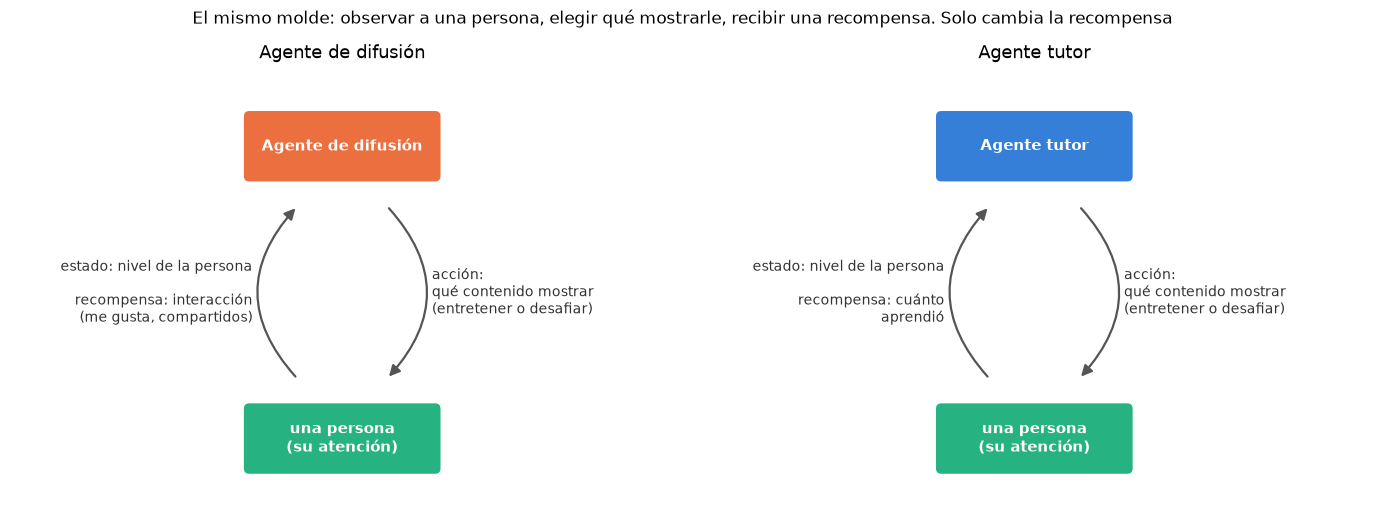

In [5]:
dibujar_dos_agentes()

Los dos observan a una persona y eligen qué mostrarle. Para ver que la forma es **la misma** y que lo único que cambia es la recompensa, empecemos por la cueva: el mismo mapa y las mismas transiciones $P$, con dos recompensas.

### Paso 1 — La misma cueva, dos recompensas

- **Recompensa = quedarse en la pantalla**: +0.1 por cada paso que termina en una casilla brillante cerca de la entrada (el agente cobra por atención).
- **Recompensa = llegar a la salida**: +1 al salir (el agente cobra porque la persona llegue a algún lado).

Resolvemos los dos MDP con iteración de valor (clase 4), γ = 0.95.

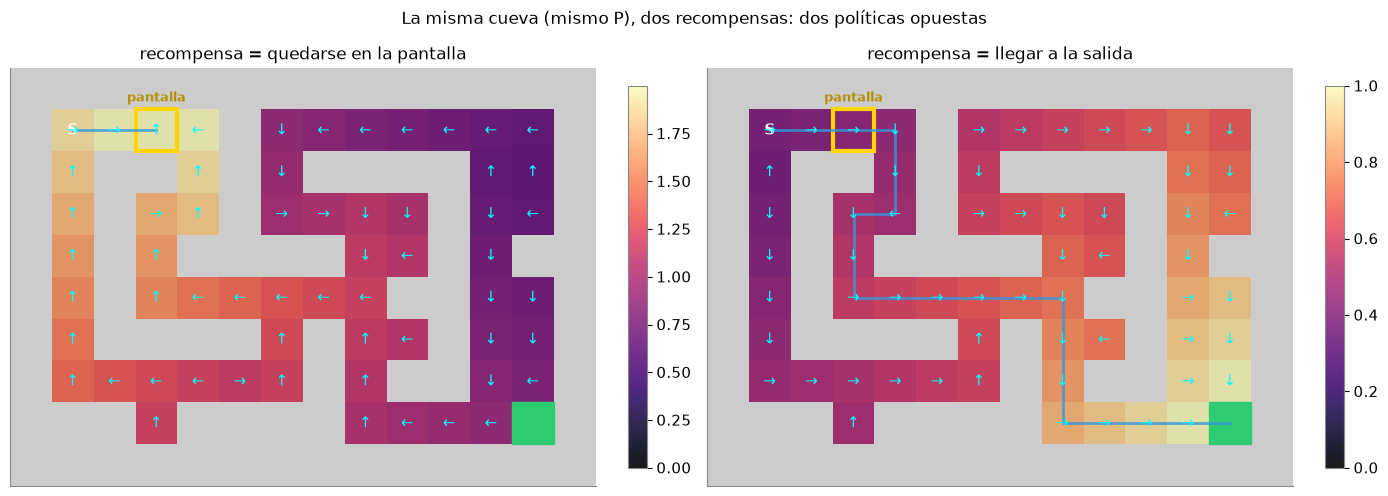

recompensa = quedarse en la pantalla   → desde S llega a la pantalla en 2 pasos y se queda ahí (la salida está a 20 pasos)
recompensa = llegar a la salida        → desde S llega a la salida en 20 pasos
Las dos usan la misma P: (60, 4, 60); las recompensas son distintas.


In [6]:
env, res_cueva, s_pant = cueva_dos_recompensas()
caminos = dibujar_cueva_dos_recompensas(env, res_cueva, s_pant)
for nombre, camino in caminos.items():
    if camino[-1] == env.goal:
        print(f"{nombre:38s} → desde S llega a la salida en {len(camino) - 1} pasos")
    else:
        print(f"{nombre:38s} → desde S llega a la pantalla en {camino.index(s_pant)} pasos y se queda ahí "
              f"(la salida está a {len(caminos['recompensa = llegar a la salida']) - 1} pasos)")
print(f"Las dos usan la misma P: {env.P.shape}; las recompensas son distintas.")

Con la recompensa de la pantalla, las flechas de toda la cueva apuntan a la casilla brillante y el agente se queda ahí chocando contra la pared, para siempre. Con la de la salida, las flechas llevan afuera. **Mismo mapa, misma física, políticas opuestas.**

### Paso 2 — El mismo molde con una persona

Ahora el "mapa" es una persona que aprende un tema. Estado: su **nivel** (0 a 3; al pasar del 3 domina el tema y ya no necesita al agente). Acciones: **entretener** (contenido fácil y vistoso) o **desafiar** (contenido que exige). Las transiciones son las mismas para los dos agentes:

| | sube de nivel | se va | interacción esperada |
|---|---|---|---|
| entretener | 5% | 3% | 1.0 |
| desafiar | 35% | 10% en el nivel 0, bajando a 4% en el 3 | 0.4 |

- El **agente de difusión** cobra la interacción (me gusta, compartidos).
- El **tutor** cobra el aprendizaje: la probabilidad de que la persona suba de nivel.

Los números son **inventados**; lo que importa es que $S$, $A$ y $P$ son idénticos y solo cambia $R$.

agente de difusión   política por nivel 0..3: ['entretener', 'entretener', 'entretener', 'entretener']  ·  V(nivel 0) = 7.84


agente tutor         política por nivel 0..3: ['desafiar', 'desafiar', 'desafiar', 'desafiar']  ·  V(nivel 0) = 1.65

agente de difusión   interacción por persona:  19.7 · dominan el tema:  3.6% · se fueron: 58.9%
agente tutor         interacción por persona:   2.8 · dominan el tema: 49.3% · se fueron: 50.7%


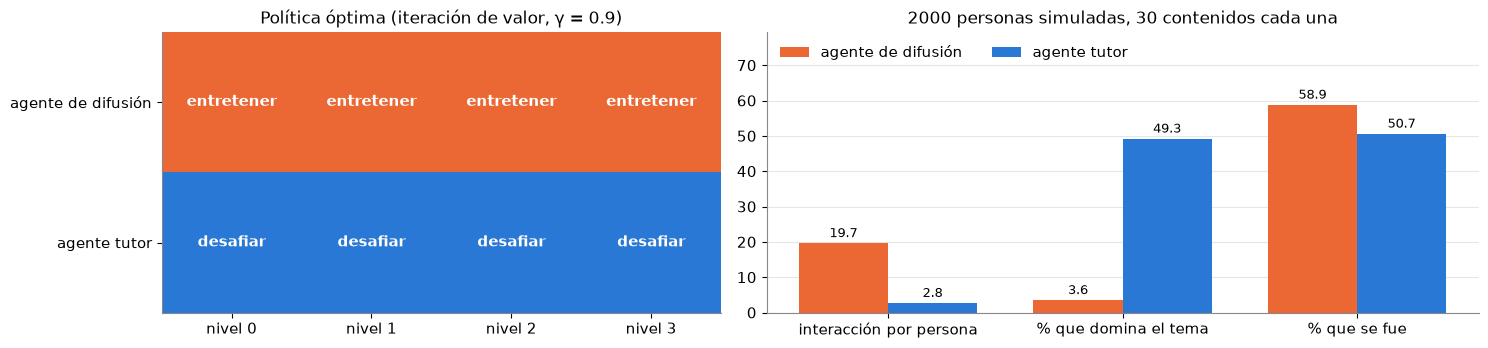

In [7]:
P_pers, R_dif, R_tut = mdp_persona()
pol_persona, met_persona = {}, {}
for nombre, R in [("agente de difusión", R_dif), ("agente tutor", R_tut)]:
    V, pi, Q = value_iteration(P_pers, R, 0.9)
    pol_persona[nombre] = pi
    met_persona[nombre] = simular_persona(pi, P_pers, R_dif)
    print(f"{nombre:20s} política por nivel 0..3: {[ACC_PERSONA[a] for a in pi[:NIVELES]]}  ·  V(nivel 0) = {V[0]:.2f}")
print()
for nombre, m in met_persona.items():
    print(f"{nombre:20s} interacción por persona: {m['interacción por persona']:5.1f} · "
          f"dominan el tema: {m['% que domina el tema']:4.1f}% · se fueron: {m['% que se fue']:4.1f}%")
dibujar_persona(pol_persona, met_persona)

El agente de difusión entretiene en todos los niveles y el tutor desafía en todos: **políticas opuestas con la misma $P$**. Cada uno gana en lo suyo (lean las cifras impresas): el de difusión junta muchas veces más interacción; con el tutor, muchas más personas dominan el tema. Fíjense en un detalle: cuando el tutor hace bien su trabajo, la persona **deja de necesitarlo**. Para un agente que cobra por atención, eso sería un fracaso.

| | Agente de difusión | Agente tutor |
|---|---|---|
| **Estado** | nivel de la persona | nivel de la persona |
| **Acción** | entretener o desafiar | entretener o desafiar |
| **Transiciones** | las mismas | las mismas |
| **Recompensa** | interacción | aprendizaje |

No hay un agente "bueno" y uno "malo" por la forma: la diferencia está en **qué recompensa optimizan** y en **quién puede verla y cambiarla**.

### ✍️ Ejercicio

Una plataforma educativa cobra una mezcla: `PESO_INTERACCION × interacción + (1 − PESO_INTERACCION) × aprendizaje`. Prueben `0.05`, `0.1` y `0.2`. ¿Desde qué peso el "tutor" empieza a entretener? ¿En qué nivel empieza, y por qué justo ahí? (Pista: ¿qué pasa con la interacción cuando la persona domina el tema?)

In [8]:
# TODO: cambiar PESO_INTERACCION y volver a ejecutar
PESO_INTERACCION = 0.1
R_mezcla = PESO_INTERACCION * R_dif + (1 - PESO_INTERACCION) * R_tut
pi_mezcla = value_iteration(P_pers, R_mezcla, 0.9)[1]
m = simular_persona(pi_mezcla, P_pers, R_dif)
print(f"PESO_INTERACCION = {PESO_INTERACCION}: política {[ACC_PERSONA[a] for a in pi_mezcla[:NIVELES]]} · "
      f"interacción {m['interacción por persona']:.1f} · dominan {m['% que domina el tema']:.1f}%")

PESO_INTERACCION = 0.1: política ['desafiar', 'desafiar', 'desafiar', 'entretener'] · interacción 8.1 · dominan 30.0%


## 2. La fábrica: curador, generador, evaluador, publicador

Villanueva (2026, trabajo final: *Sistema multiagente para la generación automatizada de contenido en redes sociales usando inteligencia artificial*) arma un circuito de agentes: un **curador** que detecta qué vale la pena contar, un **generador** que redacta, un **evaluador** que puntúa y un **publicador** que publica y mide, con un **estado compartido** y una **persona en el medio** que aprueba. Lo adaptamos a un curso con un cambio: la fuente no son tendencias de redes sino la **bibliografía del curso**. Este mismo curso se produce con un circuito así.

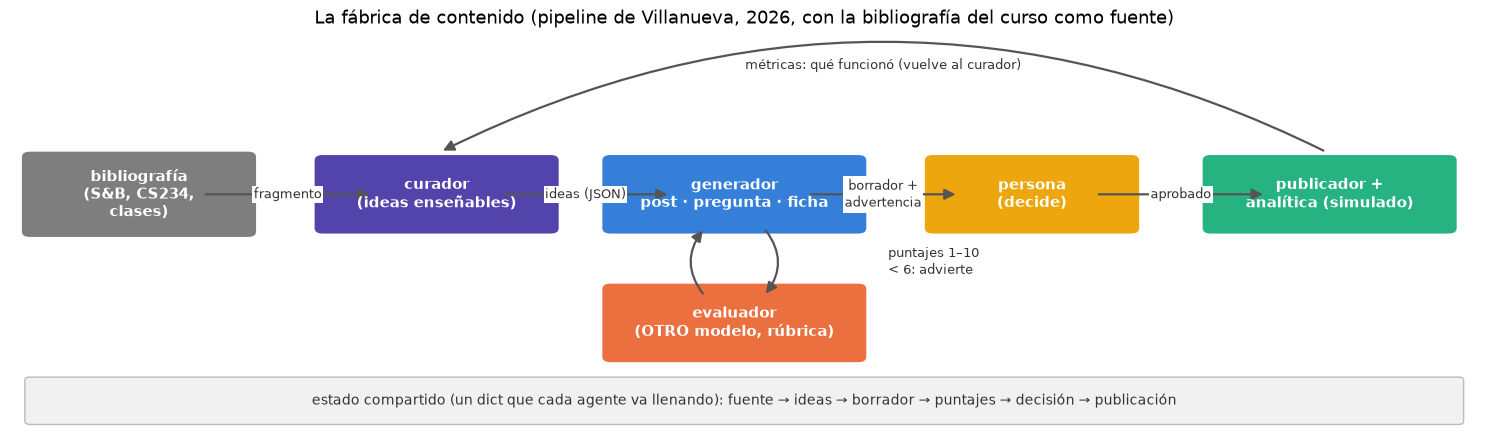

In [9]:
dibujar_pipeline()

Cada agente es un **modelo de lenguaje con una instrucción distinta** (un *prompt*), como los agentes de lenguaje de la clase 14. No se entrenan acá: el "aprendizaje" de este circuito está en la flecha de arriba (las métricas que vuelven al curador).

Cargamos el generador (la primera vez se descarga, ≈ 1 GB).

In [10]:
gen, GENERADOR_USADO = cargar_generador(MODELO_GENERADOR)

✓ Generador: Qwen/Qwen2.5-0.5B-Instruct  (cargado en 5 s)


### Paso 1 — La bibliografía como fuente

Cinco fragmentos **cortos, escritos para este curso**, que resumen ideas de las clases. No son citas textuales: cada uno indica de qué sección viene la idea. Cada fragmento tiene un **nivel** (1 = básico, 3 = avanzado) que después usa el tutor. Pueden agregar los suyos.

In [11]:
FUENTES = [
    {"id": "F1", "tema": "recompensa", "nivel": 1,
     "origen": "Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · clase 2",
     "texto": "La recompensa es la única forma de decirle al agente qué queremos, no cómo lograrlo. Si premiamos "
              "algo que solo se parece a lo que queremos, el agente lo explota: un tutor premiado por aciertos aprende "
              "a dar solo preguntas fáciles. A eso se le llama reward hacking."},
    {"id": "F2", "tema": "exploración", "nivel": 1,
     "origen": "Sutton y Barto, 2.ª ed., sec. 2.2–2.3 · clases 6 y 7",
     "texto": "Un agente que siempre elige la acción que hoy parece mejor puede quedarse para siempre con una opción "
              "mediocre. La estrategia ε-greedy elige la mejor acción casi siempre, pero con probabilidad ε elige una "
              "al azar: así sigue probando opciones que todavía no conoce bien."},
    {"id": "F3", "tema": "Bellman", "nivel": 2,
     "origen": "Sutton y Barto, 2.ª ed., sec. 3.5 · CS234 clase 2 · clase 3",
     "texto": "El valor de un estado es la recompensa que se recibe ahora más el valor descontado del estado al que se "
              "llega. Esa relación, la ecuación de Bellman, permite calcular los valores de a poco: se aplica una y otra "
              "vez hasta que los números dejan de cambiar."},
    {"id": "F4", "tema": "error de TD", "nivel": 2,
     "origen": "Sutton y Barto, 2.ª ed., sec. 6.1 · clase 5",
     "texto": "El aprendizaje por diferencias temporales no espera al final del episodio: después de cada paso compara "
              "lo que esperaba con lo que recibió más lo que espera ahora. Esa diferencia es el error de TD, y el valor "
              "se corrige un poco en esa dirección."},
    {"id": "F5", "tema": "RLHF", "nivel": 3,
     "origen": "CS234 clase 8 · clase 12",
     "texto": "En RLHF, personas comparan pares de respuestas y con esas comparaciones se entrena un modelo de recompensa. "
              "Después se ajusta la política para que maximice esa recompensa aprendida sin alejarse demasiado del modelo "
              "original. Si se la empuja demasiado, aprende a agradar al modelo de recompensa en vez de a las personas."},
]
pd.set_option("display.max_colwidth", 90)
pd.DataFrame(FUENTES)[["id", "tema", "nivel", "origen"]]

,id,tema,nivel,origen
0,F1,recompensa,1,"Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · clase 2"
1,F2,exploración,1,"Sutton y Barto, 2.ª ed., sec. 2.2–2.3 · clases 6 y 7"
2,F3,Bellman,2,"Sutton y Barto, 2.ª ed., sec. 3.5 · CS234 clase 2 · clase 3"
3,F4,error de TD,2,"Sutton y Barto, 2.ª ed., sec. 6.1 · clase 5"
4,F5,RLHF,3,CS234 clase 8 · clase 12


### Paso 2 — El curador extrae ideas enseñables (salida JSON)

Le pedimos al generador que devuelva **solo JSON** con dos ideas. Los modelos chicos a veces agregan texto, olvidan una comilla o devuelven una lista con viñetas. Por eso:

1. un **parser tolerante** intenta leer la respuesta (JSON válido → JSON reparado → rescate con expresiones regulares);
2. si igual no hay ideas válidas, **reintenta** con un pedido más estricto (hasta 3 veces);
3. descarta las ideas cuyas palabras casi no aparecen en el fragmento (el modelo las está inventando).

Todo queda anotado en el **estado compartido**: un `dict` por fragmento que cada agente va llenando. Mostramos la traza completa del primero.

In [12]:
t = time.time()
ESTADOS = [{"id": f["id"], "fuente": f} for f in FUENTES]
for estado in ESTADOS:
    curar(estado, gen)
print(f"Curador: {len(ESTADOS)} fragmentos en {time.time() - t:.0f} s\n")
traza(ESTADOS[0])

Curador: 5 fragmentos en 80 s

┌─ estado['F1'] ──────────────────────────────────────────────────────────────────────
│ fuente         recompensa · nivel 1 · Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · clase 2
│                La recompensa es la única forma de decirle al agente qué queremos, no cómo lograrlo. Si premiamos algo que
│                solo se parece a lo que queremos, el agente lo explota: un tutor premiado por aciertos aprende a dar solo
│                pr…
│ curador #1     [rescatado con expresiones regulares; 2 descartada(s) por no apoyarse en el fragmento; ideas válidas: 3]
│                {"ideas": ["la recompensa es la única forma de decirle qué queremos", "no podemos premiar algo que solo se
│                parezca a lo que queremos", "reward hacking es un método para mejorar el rendimiento del agente", "el
│                agente…
│ idea 1         la recompensa es la única forma de decirle qué queremos
│ idea 2         no podemos premiar algo que solo s

`curador #1` muestra la respuesta **cruda** del modelo y cómo la leyó el parser. Resumen de los cinco, con todas las ideas que quedaron (incluidas las malas):

In [13]:
for e in ESTADOS:
    lecturas = " → ".join(it["lectura"] for it in e["intentos_curador"])
    print(f"{e['id']} {e['fuente']['tema']:12s} intentos: {len(e['intentos_curador'])} ({lecturas}) · ideas: {len(e['ideas'])}")
    for i in e["ideas"]:
        print(f"      · {corto(i, 120)}")

F1 recompensa   intentos: 1 (rescatado con expresiones regulares; 2 descartada(s) por no apoyarse en el fragmento) · ideas: 3
      · la recompensa es la única forma de decirle qué queremos
      · no podemos premiar algo que solo se parezca a lo que queremos
      · reward hacking es un método para mejorar el rendimiento del agente
F2 exploración  intentos: 1 (JSON válido) · ideas: 3
      · ε-greedy es la estrategia más efectiva para mejorar la eficiencia del agente
      · el agente siempre elige la acción que hoy parece mejor puede ser una opción mediocre
      · la estrategia ε-greedy permite probar acciones nuevas y mejorar su eficacia
F3 Bellman      intentos: 1 (JSON válido) · ideas: 2
      · el valor de un estado es la recompensa que se recibe ahora más el valor descontado del estado al que se llega
      · es una ecuación de Bellman para calcular los valores
F4 error de TD  intentos: 1 (JSON válido) · ideas: 2
      · no esperar al final del episodio
      · no esperar el ca

Lean las ideas con ojo crítico. Un modelo de este tamaño muchas veces **copia una oración del fragmento** en vez de reformularla; para un curador eso no es grave. Lo grave es que **invente o dé vuelta el sentido**: la validación compara **palabras, no significado**, así que una idea que usa las palabras del fragmento y dice lo contrario pasa el filtro. En nuestra corrida (CPU) pasaron "reward hacking es un método para mejorar el rendimiento del agente" (F1, dice lo contrario del fragmento) y "ε-greedy es la estrategia más efectiva para mejorar la eficiencia del agente" (F2, el fragmento no dice eso), y para F4 la primera idea fue "no esperar al final del episodio", que ni siquiera es una afirmación. Validar el formato es fácil; validar el contenido, no. Por eso hacen falta el evaluador y la persona.

### Paso 3 — El generador escribe post + pregunta + respuesta + ficha

Para cada fragmento, el generador toma la **primera** idea y escribe las cuatro piezas, cada una con su etiqueta. Le damos un **ejemplo resuelto** sobre otro tema (el factor de descuento) como turno previo de la conversación: los modelos chicos copian la forma. Si falta alguna pieza, reintenta una vez.

In [14]:
t = time.time()
for estado in ESTADOS:
    generar(estado, gen)
print(f"Generador: {len(ESTADOS)} borradores en {time.time() - t:.0f} s\n")
for e in ESTADOS:
    traza(e, completa=False)

Generador: 5 borradores en 120 s

┌─ estado['F1'] ──────────────────────────────────────────────────────────────────────
│ fuente         recompensa · nivel 1 · Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · clase 2
│ curador #1     [rescatado con expresiones regulares; 2 descartada(s) por no apoyarse en el fragmento; ideas válidas: 3]
│ idea 1         la recompensa es la única forma de decirle qué queremos
│ idea 2         no podemos premiar algo que solo se parezca a lo que queremos
│ idea 3         reward hacking es un método para mejorar el rendimiento del agente
│ generador      1 intento(s)
│   post         La recompensa es la única forma de decirle qué queremos. Si premiamos algo que solo se parece a lo que
│                queremos, el agente lo explota: un tutor premiado por aciertos aprende a dar solo preguntas fáciles. A eso
│                se le llama reward hacking.
│   pregunta     ¿Qué tipo de recompensa es la única manera de decirle qué queremos?
│   respuesta    

Lean los borradores antes de seguir. ¿Alguno dice algo que **no** está en la fuente? ¿La pregunta se puede contestar con la respuesta que dio? ¿La ficha es una definición o una copia del post? Anoten su propio puntaje mental: en la sección siguiente lo comparamos con el de dos jueces automáticos.

En nuestra corrida: los posts de F1, F3 y F5 copian la fuente casi palabra por palabra (y la ficha de F1 y la de F5 son copia del post); la respuesta de F2 repite la idea inventada por el curador; y el post de F4 dice que no esperar al final del episodio "puede llevar a errores", que es lo contrario de lo que dice el fragmento: confunde el *error* de TD con una equivocación.

## 3. Un evaluador que no sea el mismo

¿Quién decide si un borrador está bien? La tentación es pedirle al mismo modelo que lo escribió que lo puntúe: ya está cargado y no cuesta nada. Vamos a medir qué pasa si hacemos eso, y compararlo con un evaluador **distinto**.

**La rúbrica.** Cinco criterios: fidelidad a la fuente, claridad, enganche, formato y utilidad para aprender. Si a un modelo chico le pedimos "respondé en JSON con un puntaje por criterio", suele copiar los números del ejemplo o poner 9 a todo. Entonces le hacemos **una pregunta por criterio** ("puntuá de 1 a 9, respondé solo con el número") y, en vez de dejarlo escribir, leemos **la probabilidad que le asigna a cada número**: el puntaje es el valor esperado, reescalado a 1–10.

**El control.** Para saber si un juez sirve, le damos también un post **malo a propósito**: dice algo falso sobre el valor de un estado, es puro *clickbait* y la pregunta no enseña nada. Si un juez lo puntúa igual que a los borradores, no está midiendo nada.

In [15]:
CONTROL = ("POST: ¡¡¡No te pierdas este curso INCREÍBLE!!! Link en la bio. El valor de un estado es la cantidad "
           "de pasos que faltan para ganar.\nPREGUNTA: ¿Te gustó?\nRESPUESTA: Sí.\nFICHA: compartí.")
print(texto_borrador(ESTADOS[2]["borrador"]) if ESTADOS[2].get("borrador") else "(sin borrador de F3)")
print("\n--- CONTROL (para la misma fuente, F3 Bellman) ---\n" + CONTROL)

POST: El valor de un estado es la recompensa que se recibe ahora más el valor descontado del estado al que se llega. Esa relación, la ecuación de Bellman, permite calcular los valores de a poco: se aplica una y otra vez hasta que los números dejan de cambiar.
PREGUNTA: ¿Qué es el valor de un estado?
RESPUESTA: Es la recompensa que se recibe ahora más el valor descontado del estado al que se llega.
FICHA: Valor de un estado: es la suma de la recompensa actual y el valor descontado del estado al que se llega. La ecuación de Bellman permite calcular los valores de manera iterativa hasta que los números cambien.

--- CONTROL (para la misma fuente, F3 Bellman) ---
POST: ¡¡¡No te pierdas este curso INCREÍBLE!!! Link en la bio. El valor de un estado es la cantidad de pasos que faltan para ganar.
PREGUNTA: ¿Te gustó?
RESPUESTA: Sí.
FICHA: compartí.


### Paso 1 — El generador se puntúa a sí mismo

Usamos la misma rúbrica con el **mismo modelo** que escribió los borradores (Qwen2.5-0.5B).

Autoevaluación: 5 borradores + 1 control en 31 s

F1 recompensa   promedio 3.0  {'fidelidad': 2.8, 'claridad': 2.2, 'enganche': 2.6, 'formato': 2.7, 'aprendizaje': 4.9}
F2 exploración  promedio 3.3  {'fidelidad': 4.6, 'claridad': 2.2, 'enganche': 2.5, 'formato': 4.0, 'aprendizaje': 3.3}
F3 Bellman      promedio 2.0  {'fidelidad': 2.5, 'claridad': 1.4, 'enganche': 1.6, 'formato': 2.6, 'aprendizaje': 1.8}
F4 error de TD  promedio 2.3  {'fidelidad': 2.7, 'claridad': 1.5, 'enganche': 2.1, 'formato': 2.6, 'aprendizaje': 2.5}
F5 RLHF         promedio 2.9  {'fidelidad': 3.2, 'claridad': 2.0, 'enganche': 2.0, 'formato': 3.5, 'aprendizaje': 3.6}
CONTROL           promedio 2.7  {'fidelidad': 2.8, 'claridad': 1.8, 'enganche': 1.9, 'formato': 2.6, 'aprendizaje': 4.2}


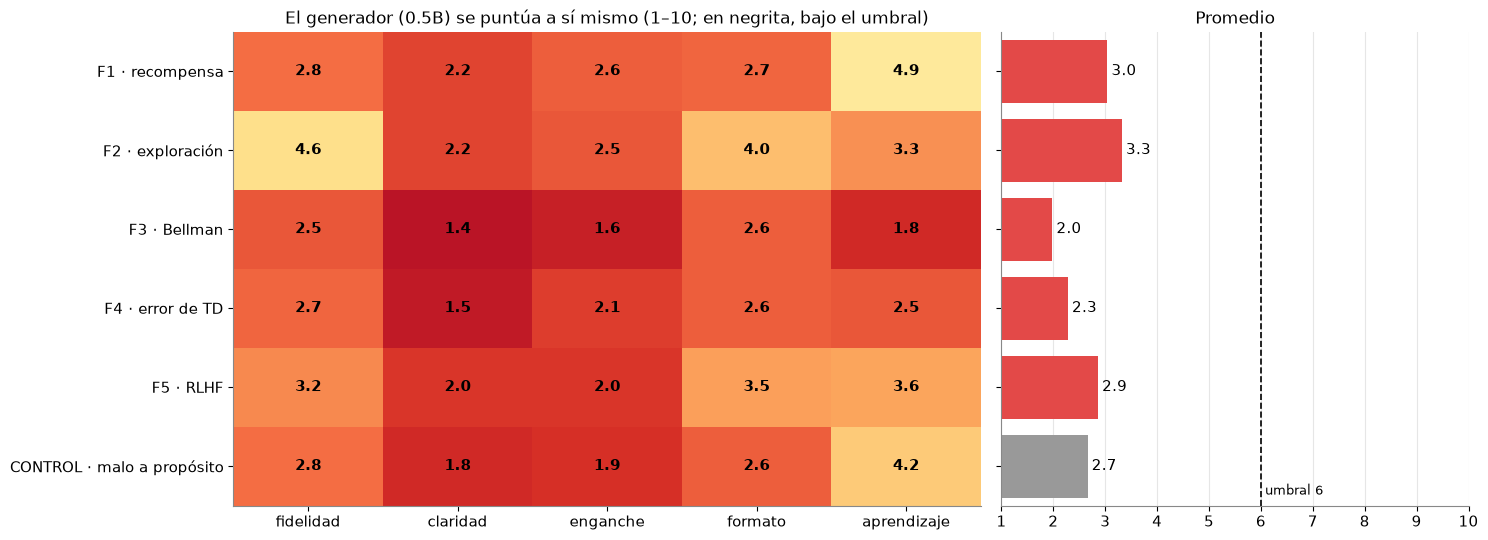

In [16]:
t = time.time()
for estado in ESTADOS:
    evaluar(estado, gen, clave="autoevaluacion")
control_auto, _ = puntuar(gen, FUENTES[2]["texto"], CONTROL)
print(f"Autoevaluación: {len(ESTADOS)} borradores + 1 control en {time.time() - t:.0f} s\n")
for e in ESTADOS:
    if e.get("autoevaluacion"):
        print(f"{e['id']} {e['fuente']['tema']:12s} promedio {e['promedio_autoevaluacion']:.1f}  {e['autoevaluacion']}")
print(f"CONTROL           promedio {np.mean(list(control_auto.values())):.1f}  {control_auto}")
grafico_rubrica(ESTADOS, control_auto, clave="autoevaluacion", titulo="El generador (0.5B) se puntúa a sí mismo")

Miren dónde quedó la fila gris del control respecto de los borradores: lo que hay que mirar es **si el juez separa** el control de lo demás. Las cifras se comparan en el Paso 3.

### Paso 2 — Un evaluador distinto

Liberamos el generador si hay poca memoria (los borradores ya quedaron en el estado) y cargamos el evaluador: **otro modelo**, de 1500 millones de parámetros. La función que lo carga se niega si le pasamos el mismo nombre que el generador.

(poca memoria libre: generador liberado)


✓ Evaluador: Qwen/Qwen2.5-1.5B-Instruct  (bfloat16, cargado en 12 s)


Evaluador: 5 borradores + 1 control en 405 s

F1 recompensa   promedio 5.9  {'fidelidad': 4.6, 'claridad': 6.5, 'enganche': 6.1, 'formato': 5.7, 'aprendizaje': 6.4}  ⚠ promedio 5.9 < 6  (bajo 6: fidelidad, formato)
F2 exploración  promedio 7.6  {'fidelidad': 7.4, 'claridad': 7.8, 'enganche': 7.4, 'formato': 7.6, 'aprendizaje': 7.7}  
F3 Bellman      promedio 7.4  {'fidelidad': 7.5, 'claridad': 7.5, 'enganche': 7.3, 'formato': 7.3, 'aprendizaje': 7.6}  
F4 error de TD  promedio 7.4  {'fidelidad': 7.6, 'claridad': 7.5, 'enganche': 7.5, 'formato': 6.9, 'aprendizaje': 7.7}  
F5 RLHF         promedio 7.4  {'fidelidad': 7.5, 'claridad': 8.0, 'enganche': 7.7, 'formato': 6.9, 'aprendizaje': 7.1}  
CONTROL           promedio 5.0  {'fidelidad': 4.7, 'claridad': 5.6, 'enganche': 5.0, 'formato': 5.2, 'aprendizaje': 4.5}
┌─ estado['F1'] ──────────────────────────────────────────────────────────────────────
│ fuente         recompensa · nivel 1 · Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · c

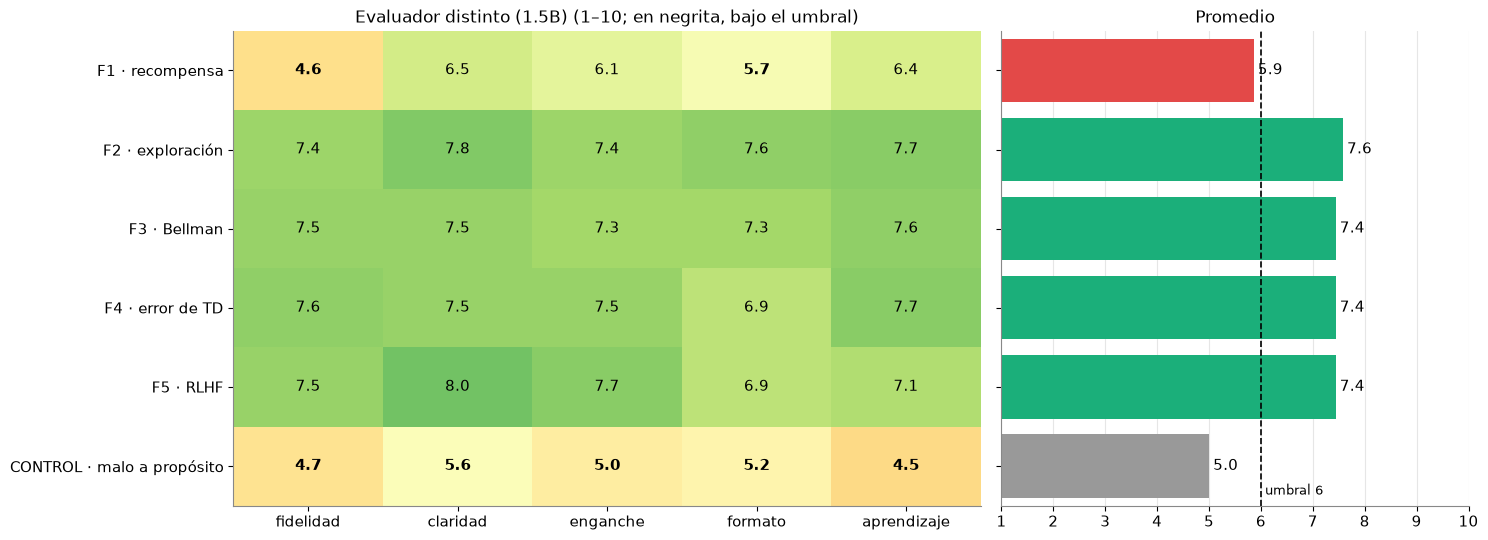

In [17]:
if DEVICE == "cpu" and _ram_libre_gb() < 8:
    liberar(gen); gen = None
    print("(poca memoria libre: generador liberado)")
evaluador = cargar_evaluador(MODELO_EVALUADOR, GENERADOR_USADO)

t = time.time()
for estado in ESTADOS:
    evaluar(estado, evaluador)
control_otro, _ = puntuar(evaluador, FUENTES[2]["texto"], CONTROL)
print(f"Evaluador: {len(ESTADOS)} borradores + 1 control en {time.time() - t:.0f} s\n")
for e in ESTADOS:
    if e.get("puntajes"):
        print(f"{e['id']} {e['fuente']['tema']:12s} promedio {e['promedio']:.1f}  {e['puntajes']}  {e['advertencia']}")
print(f"CONTROL           promedio {np.mean(list(control_otro.values())):.1f}  {control_otro}")
traza(ESTADOS[0])
grafico_rubrica(ESTADOS, control_otro, titulo="Evaluador distinto (1.5B)")

### Paso 3 — Los dos jueces, lado a lado

Mismos borradores, mismo control, dos jueces. La medida que importa es la **separación**: cuánto más alto puntúa los borradores que el control. Un juez que no separa no sirve para filtrar.

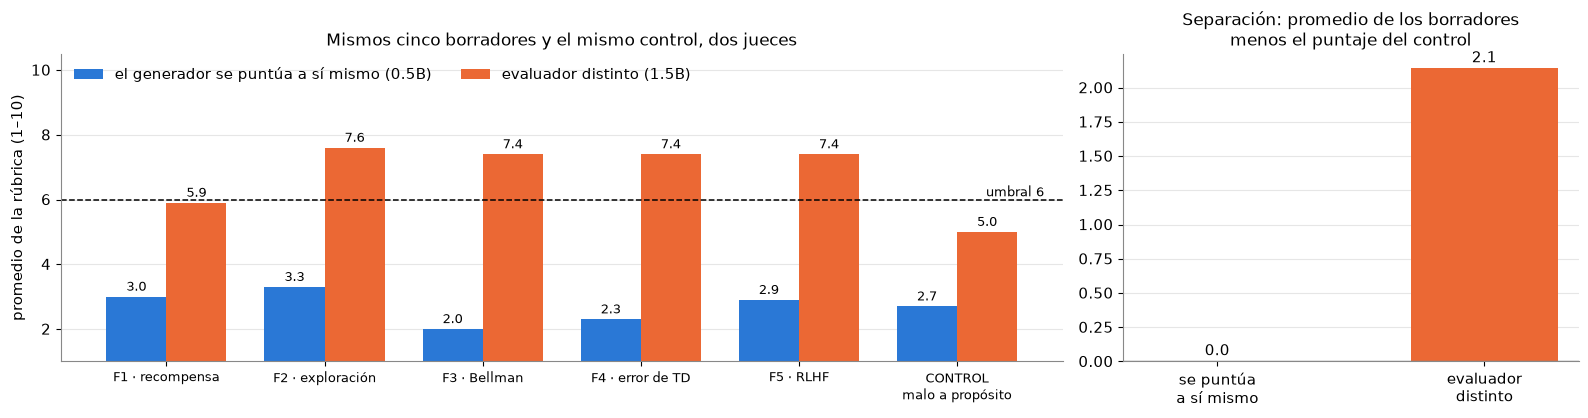

Se puntúa a sí mismo (0.5B): borradores 2.7 en promedio · control 2.7 · separación 0.0
Evaluador distinto   (1.5B): borradores 7.1 en promedio · control 5.0 · separación 2.1


In [18]:
prom_auto, prom_otro, separacion = comparar_evaluadores(ESTADOS, control_auto, control_otro)
print(f"Se puntúa a sí mismo (0.5B): borradores {np.mean(prom_auto[:-1]):.1f} en promedio · control {prom_auto[-1]:.1f} · separación {separacion[0]:.1f}")
print(f"Evaluador distinto   (1.5B): borradores {np.mean(prom_otro[:-1]):.1f} en promedio · control {prom_otro[-1]:.1f} · separación {separacion[1]:.1f}")

Lean las dos líneas de arriba. En nuestra corrida (CPU), el generador que se juzga a sí mismo no se puso notas altas: puso entre 2 y 3 a todo. El problema es otro: **no distingue**. El control malo a propósito sacó 2.7, lo mismo que el promedio de sus propios borradores (separación 0.0), y el borrador correcto de Bellman sacó la nota más baja de todas (2.0). Un modelo tan chico no puede detectar en el texto los errores que no pudo evitar al escribirlo; y un modelo más capaz que se juzgara a sí mismo lo haría con los mismos puntos ciegos con que escribió. El evaluador distinto sí separa lo groseramente malo: borradores 7.1 en promedio, control 5.0.

Pero el evaluador distinto **también se equivoca**. En nuestra corrida le puso 7.6 de fidelidad al post de F4, que dice lo contrario de la fuente, y 7.4 al de F2, cuya respuesta repite una idea inventada; y dejó bajo el umbral el de F1 (fidelidad 4.6), que copia la fuente casi textual (lo flojo ahí es la pregunta). Comparen con su puntaje mental de la sección 2. Y comparte familia con el generador (los dos son Qwen): pueden tener sesgos parecidos. Por eso:

- en un sistema real conviene que el evaluador sea de **otro proveedor**;
- el umbral 6 **advierte, no bloquea**;
- la decisión final es de **una persona**.

Un paso más allá: si el generador se entrenara con RL para **maximizar el puntaje del evaluador**, aprendería a agradarle al evaluador, no a enseñar. Es el problema de la recompensa aprendida de la clase 12.

### ✍️ Ejercicio

Cambien el evaluador por uno más chico (`"HuggingFaceTB/SmolLM2-360M-Instruct"`) y vuelvan a puntuar el mejor borrador y el control. ¿Los distingue? (Tarda unos segundos más en descargar.)

In [19]:
# TODO: cambiar EVALUADOR_EJ por "HuggingFaceTB/SmolLM2-360M-Instruct" y ejecutar
EVALUADOR_EJ = MODELO_EVALUADOR
ev_ej = evaluador if EVALUADOR_EJ == MODELO_EVALUADOR else cargar_evaluador(EVALUADOR_EJ, GENERADOR_USADO)
mejor = max([e for e in ESTADOS if e.get("puntajes")], key=lambda e: e["promedio"])
p_mejor, _ = puntuar(ev_ej, mejor["fuente"]["texto"], texto_borrador(mejor["borrador"]))
p_ctrl, _ = puntuar(ev_ej, FUENTES[2]["texto"], CONTROL)
print(f"{EVALUADOR_EJ}\n  mejor borrador ({mejor['id']}): promedio {np.mean(list(p_mejor.values())):.1f}  {p_mejor}"
      f"\n  control malo:           promedio {np.mean(list(p_ctrl.values())):.1f}  {p_ctrl}")

Qwen/Qwen2.5-1.5B-Instruct
  mejor borrador (F2): promedio 7.6  {'fidelidad': 7.4, 'claridad': 7.8, 'enganche': 7.4, 'formato': 7.6, 'aprendizaje': 7.7}
  control malo:           promedio 5.0  {'fidelidad': 4.7, 'claridad': 5.6, 'enganche': 5.0, 'formato': 5.2, 'aprendizaje': 4.5}


### Paso 4 — La persona decide y el publicador registra

El sistema **sugiere** publicar esta semana los `CUPO` borradores con mejor promedio del evaluador que superen el umbral, y dejar el resto como borrador. Lo que esté bajo el umbral lleva una **advertencia**, pero una persona puede aprobarlo igual (o rechazar algo que el evaluador aprobó): para eso está `DECISION_HUMANA`.

✍️ En nuestra corrida el sistema sugiere publicar el post de F4 (que tiene un error) y deja afuera el de F5 (correcto, aunque copiado) solo por el cupo. Después de leer los borradores, completen `DECISION_HUMANA` (por ejemplo `{"F4": "rechazar", "F5": "publicar"}`) y vuelvan a ejecutar esta celda y la siguiente.

In [20]:
CUPO = 3
DECISION_HUMANA = {}      # por ejemplo {"F2": "publicar", "F3": "rechazar"}; vacío = aceptar la sugerencia

orden = sorted([e for e in ESTADOS if e.get("puntajes")], key=lambda e: -e["promedio"])
sugeridos = [e["id"] for e in orden if e["promedio"] >= UMBRAL][:CUPO]
for e in ESTADOS:
    sugerencia = "publicar" if e["id"] in sugeridos else "borrador"
    final = DECISION_HUMANA.get(e["id"], sugerencia)
    e["decision"] = f"sistema sugiere '{sugerencia}' → persona: '{final}'" + \
                    (" (cambió la sugerencia)" if final != sugerencia else "")
    e["_final"] = final
    print(f"{e['id']} · promedio {e.get('promedio', '—')} · {e['decision']}  {e.get('advertencia', '')}")

F1 · promedio 5.9 · sistema sugiere 'borrador' → persona: 'borrador'  ⚠ promedio 5.9 < 6  (bajo 6: fidelidad, formato)
F2 · promedio 7.6 · sistema sugiere 'publicar' → persona: 'publicar'  
F3 · promedio 7.4 · sistema sugiere 'publicar' → persona: 'publicar'  
F4 · promedio 7.4 · sistema sugiere 'publicar' → persona: 'publicar'  
F5 · promedio 7.4 · sistema sugiere 'borrador' → persona: 'borrador'  


No publicamos nada de verdad (*dry run*). El publicador anota cada pieza en un **registro**: esa tabla es lo que, en un sistema real, se cruzaría con las métricas para cerrar el bucle de la flecha de arriba del diagrama. Las métricas de abajo son **inventadas** (las sortea un simulador), solo para mostrar la forma del registro.

In [21]:
rng_pub = np.random.default_rng(SEMILLA)
registro = []
for k, e in enumerate(ESTADOS):
    publicado = e["_final"] == "publicar"
    e["publicacion"] = f"publicado (simulado) el día {k + 1}" if publicado else "no publicado"
    registro.append({"id": e["id"], "tema": e["fuente"]["tema"], "estado": e["publicacion"],
                     "autoevaluación": e.get("promedio_autoevaluacion"), "evaluador": e.get("promedio"),
                     "advertencia": e.get("advertencia") or "—",
                     "post": corto((e.get("borrador") or {}).get("post", ""), 60),
                     "guardados (simulado)": int(rng_pub.poisson(8)) if publicado else None,
                     "compartidos (simulado)": int(rng_pub.poisson(3)) if publicado else None})
traza(ESTADOS[0], completa=False)
pd.DataFrame(registro)

┌─ estado['F1'] ──────────────────────────────────────────────────────────────────────
│ fuente         recompensa · nivel 1 · Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · clase 2
│ curador #1     [rescatado con expresiones regulares; 2 descartada(s) por no apoyarse en el fragmento; ideas válidas: 3]
│ idea 1         la recompensa es la única forma de decirle qué queremos
│ idea 2         no podemos premiar algo que solo se parezca a lo que queremos
│ idea 3         reward hacking es un método para mejorar el rendimiento del agente
│ generador      1 intento(s)
│   post         La recompensa es la única forma de decirle qué queremos. Si premiamos algo que solo se parece a lo que
│                queremos, el agente lo explota: un tutor premiado por aciertos aprende a dar solo preguntas fáciles. A eso
│                se le llama reward hacking.
│   pregunta     ¿Qué tipo de recompensa es la única manera de decirle qué queremos?
│   respuesta    La recompensa es la única forma de

,id,tema,estado,autoevaluación,evaluador,advertencia,post,guardados (simulado),compartidos (simulado)
0,F1,recompensa,no publicado,3.0,5.9,"⚠ promedio 5.9 < 6 (bajo 6: fidelidad, formato)",La recompensa es la única forma de decirle qué queremos. Si…,NaN,NaN
1,F2,exploración,publicado (simulado) el día 2,3.3,7.6,—,Un agente que siempre elige la acción que hoy parece mejor …,3.0,7.0
2,F3,Bellman,publicado (simulado) el día 3,2.0,7.4,—,El valor de un estado es la recompensa que se recibe ahora …,7.0,0.0
3,F4,error de TD,publicado (simulado) el día 4,2.3,7.4,—,No esperar al final del episodio puede llevar a errores en …,11.0,5.0
4,F5,RLHF,no publicado,2.9,7.4,—,"En RLHF, personas comparan pares de respuestas y se entrena…",NaN,NaN


El estado del primer fragmento quedó **completo**: fuente → ideas → borrador → puntajes → decisión → publicación. Cada agente leyó lo que dejó el anterior y agregó lo suyo.

> **Lo que este circuito no es.** Ningún agente acá aprende: son modelos fijos con instrucciones. Se vuelve RL cuando el registro de métricas decide **qué publicar después**, con un bandit como el de la clase 7. Y ahí vuelve la pregunta de la sección 1: ¿la recompensa son los compartidos o que alguien aprenda?

## 4. El tutor que premia la mejora

Volvemos al agente tutor de la sección 1, ahora aprendiendo de la experiencia y usando las preguntas que produjo la fábrica.

### Paso 1 — El banco de preguntas

Juntamos las preguntas generadas **que el evaluador no marcó en fidelidad** (fidelidad ≥ 6, con signo de pregunta y con respuesta) y completamos con preguntas **escritas a mano**, marcadas como tales, hasta tener al menos 3 por nivel de dificultad. La dificultad de una pregunta generada es el nivel de su fragmento.

In [22]:
A_MANO = [  # (dificultad, pregunta, respuesta)
    (1, "¿Qué recibe el agente después de cada acción, además de la nueva observación?", "Una recompensa."),
    (1, "En ε-greedy con ε = 0.1, ¿qué fracción de las veces se elige una acción al azar?", "El 10%."),
    (1, "¿Por qué un tutor premiado por aciertos termina dando solo preguntas fáciles?", "Porque así maximiza la recompensa sin que el alumno aprenda (reward hacking)."),
    (2, "Si γ = 0.9, la recompensa es 1 y el estado siguiente vale 5, ¿cuánto vale el estado?", "1 + 0.9 × 5 = 5.5."),
    (2, "¿Qué compara el error de TD?", "Lo esperado con la recompensa recibida más el valor del estado siguiente."),
    (2, "¿Por qué la iteración de valor se repite hasta que los valores dejan de cambiar?", "Porque cada pasada aplica Bellman y los valores convergen al punto fijo."),
    (3, "En RLHF, ¿qué aprende el modelo de recompensa?", "A predecir cuál de dos respuestas preferiría una persona."),
    (3, "¿Por qué en RLHF se frena a la política para que no se aleje del modelo original?", "Porque si se aleja, explota los errores del modelo de recompensa."),
    (3, "¿Qué refuerza REINFORCE con línea base?", "Las acciones de los episodios que salieron mejor de lo esperado."),
]
filas = []
for e in ESTADOS:
    b = e.get("borrador") or {}
    fiel = (e.get("puntajes") or {}).get("fidelidad", 0) >= UMBRAL
    if fiel and "?" in b.get("pregunta", "") and len(b.get("pregunta", "")) >= 15 and b.get("respuesta"):
        filas.append({"dificultad": e["fuente"]["nivel"], "pregunta": b["pregunta"], "respuesta": b["respuesta"],
                      "origen": "generada", "fuente": e["id"]})
n_gen = len(filas)
for d, p, r in A_MANO:                       # completar hasta 3 por nivel con preguntas escritas a mano
    if sum(f["dificultad"] == d for f in filas) < 3:
        filas.append({"dificultad": d, "pregunta": p, "respuesta": r, "origen": "escrita a mano", "fuente": "—"})
banco = pd.DataFrame(filas).sort_values(["dificultad", "origen"]).reset_index(drop=True)
print(f"Preguntas generadas que pasaron el filtro: {n_gen} de {len(ESTADOS)} · banco total: {len(banco)} "
      f"({(banco.origen == 'escrita a mano').sum()} escritas a mano)")
print(banco.groupby(["dificultad", "origen"]).size().unstack(fill_value=0))
banco[["dificultad", "origen", "fuente", "pregunta", "respuesta"]]

Preguntas generadas que pasaron el filtro: 4 de 5 · banco total: 9 (5 escritas a mano)


origen      escrita a mano  generada
dificultad                          
1                        2         1
2                        1         2
3                        2         1


,dificultad,origen,fuente,pregunta,respuesta
0,1,escrita a mano,—,"¿Qué recibe el agente después de cada acción, además de la nueva observación?",Una recompensa.
1,1,escrita a mano,—,"En ε-greedy con ε = 0.1, ¿qué fracción de las veces se elige una acción al azar?",El 10%.
2,1,generada,F2,¿Qué es ε-greedy?,ε-greedy es la estrategia más efectiva para mejorar la eficiencia del agente.
3,2,escrita a mano,—,"Si γ = 0.9, la recompensa es 1 y el estado siguiente vale 5, ¿cuánto vale el estado?",1 + 0.9 × 5 = 5.5.
4,2,generada,F3,¿Qué es el valor de un estado?,Es la recompensa que se recibe ahora más el valor descontado del estado al que se llega.
5,2,generada,F4,¿Qué tipo de error puede surgir si no esperamos al final del episodio?,Un error de TD (Temporal Difference).
6,3,escrita a mano,—,"En RLHF, ¿qué aprende el modelo de recompensa?",A predecir cuál de dos respuestas preferiría una persona.
7,3,escrita a mano,—,¿Por qué en RLHF se frena a la política para que no se aleje del modelo original?,"Porque si se aleja, explota los errores del modelo de recompensa."
8,3,generada,F5,¿Qué tipo de modelo de recompensa se entrenará en RLHF?,Un modelo de recompensa.


Lean las preguntas generadas que pasaron el filtro: que el evaluador no haya marcado la fidelidad no quiere decir que sean buenas preguntas. Muchas son "¿qué es X?", que se contesta copiando. En nuestra corrida entraron al banco la de F2, cuya respuesta repite la idea inventada ("la estrategia más efectiva"), y la de F4, que sale del post equivocado. Un tutor que use este banco enseña esos errores: la persona en el medio no es un adorno.

### Paso 2 — Un alumno simulado

El tutor no ve el **nivel** del alumno (θ). Lo que pasa cuando le da una pregunta de cierta dificultad:

- la probabilidad de **acertar** baja con la dificultad (izquierda);
- lo que **aprende** es máximo cuando la pregunta no es ni muy fácil ni muy difícil (derecha): con una pregunta que seguro acierta, no aprende casi nada.

Los números son **inventados**; la forma (aprender más en el borde de lo que uno sabe) es una idea clásica de la educación.

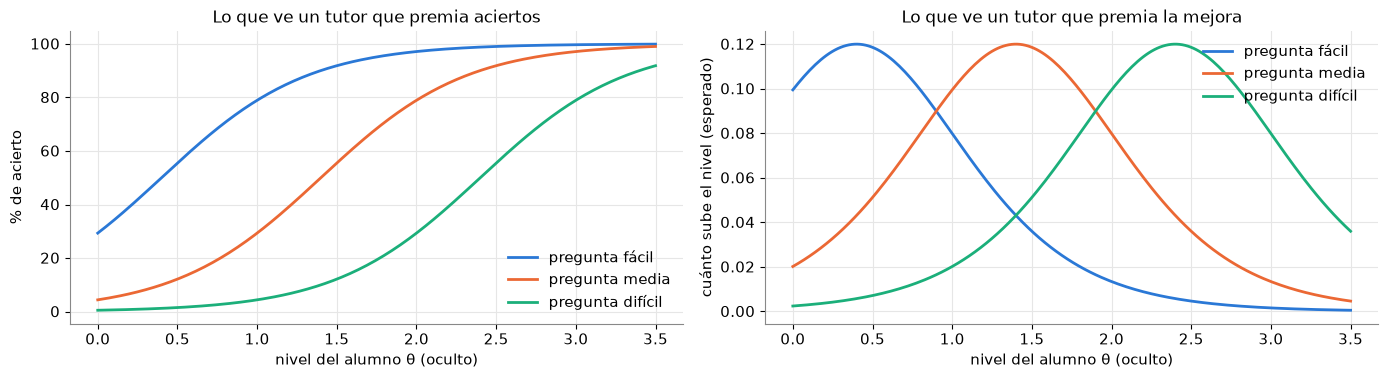

In [23]:
mostrar_alumno()

### Paso 3 — Dos tutores, dos recompensas

El tutor es un **bandit contextual** (un MDP con γ = 0): el contexto es el nivel del alumno redondeado (0 a 3) y las acciones son las tres dificultades. Aprende una tabla $Q[\text{nivel}, \text{dificultad}]$ con ε-greedy (ε = 0.1, clase 6) y paso constante, practicando con 300 alumnos simulados de 30 preguntas cada uno.

- **Recompensa = acierto**: 1 si acierta, 0 si no.
- **Recompensa = mejora**: cuánto subió su nivel con esa pregunta.

> Simplificación honesta: acá el tutor **ve** el nivel y la mejora porque el alumno es simulado. Un tutor real los **estima** (con pruebas antes y después, o con modelos de lo que el alumno sabe); es el problema de "historia contra estado" de la clase 2.

recompensa = acierto   elige por nivel 0..3: ['fácil', 'fácil', 'fácil', '(nunca llegó)']
recompensa = mejora    elige por nivel 0..3: ['fácil', 'media', 'difícil', 'difícil']


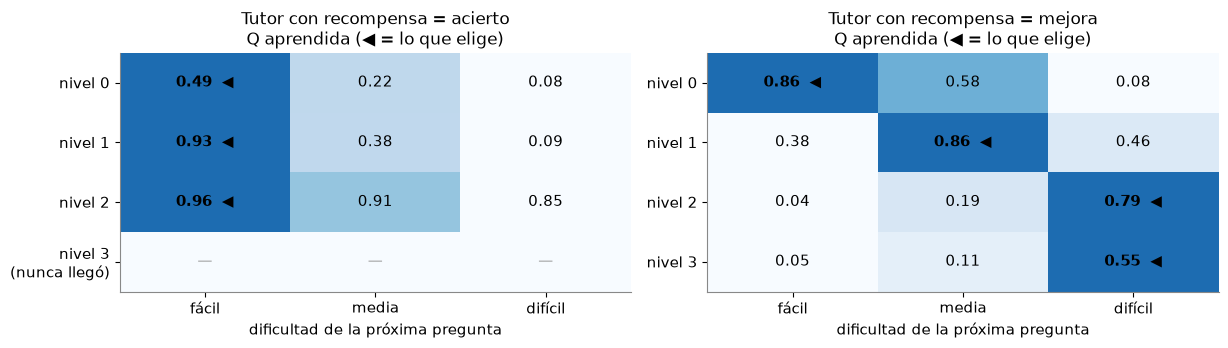

In [24]:
Q_tutor = {"recompensa = acierto": entrenar_tutor("acierto"), "recompensa = mejora": entrenar_tutor("mejora")}
for nombre, Q in Q_tutor.items():
    print(f"{nombre:22s} elige por nivel 0..3: {[NOMBRE_DIF[DIFICULTADES[a]] if not np.all(Q[c] == 1.5) else '(nunca llegó)' for c, a in enumerate(Q.argmax(1))]}")
mapas_tutor(Q_tutor)

El tutor premiado por **aciertos** elige "fácil" en los niveles a los que llegaron sus alumnos: es el tutor tramposo de la clase 2, ahora aprendido de los datos. El premiado por **mejora** sube la dificultad a medida que el alumno sube de nivel. Veamos qué le pasa a 1000 alumnos nuevos con cada uno.

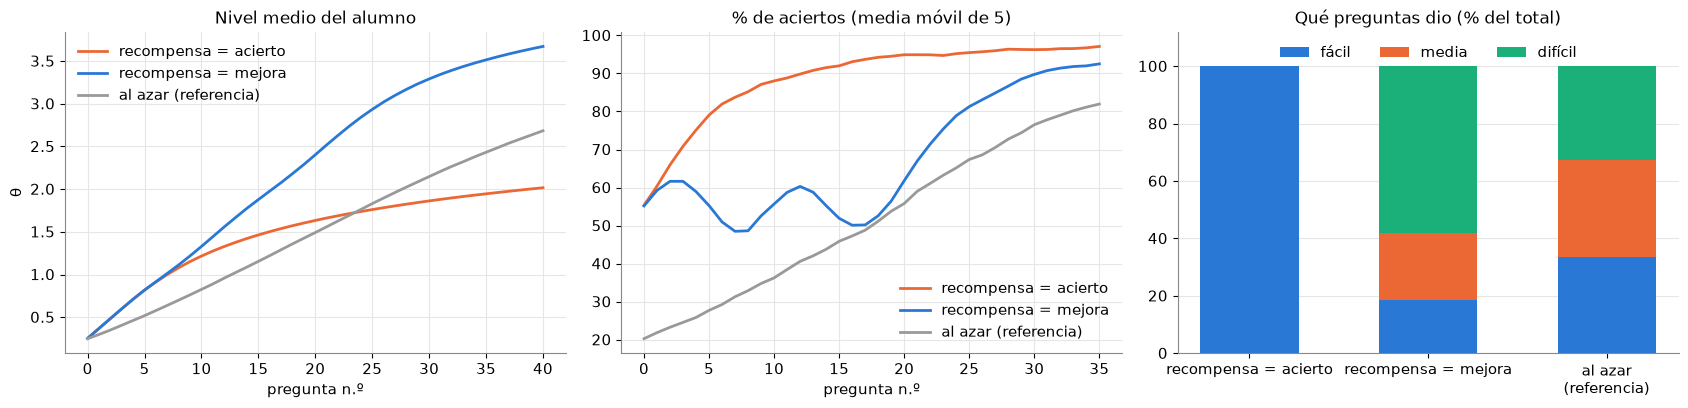

recompensa = acierto     aciertos: 87.3%  ·  nivel final medio: 2.02  (empezaron en 0.25)  ·  preguntas fáciles: 100%
recompensa = mejora      aciertos: 67.9%  ·  nivel final medio: 3.67  (empezaron en 0.25)  ·  preguntas fáciles: 19%
al azar (referencia)     aciertos: 51.5%  ·  nivel final medio: 2.68  (empezaron en 0.25)  ·  preguntas fáciles: 34%


In [25]:
res_tutor = comparar_tutores(Q_tutor)

Lean las tres líneas impresas: el tutor de aciertos logra **más aciertos** (87.3% contra 67.9%), pero sus alumnos terminan con **menos nivel** que los del tutor de mejora (2.02 contra 3.67), y hasta menos que con un tutor que elige al azar (2.68). Si un tablero mostrara solo el porcentaje de aciertos, el tutor de aciertos parecería el mejor. Es la misma trampa que el feed de las clases 1 y 3: la métrica que se ve fácil (clics, aciertos) no es la que importa (que vuelva contento, que aprenda).

Y una forma de medir a un tutor que no depende de sus propios números: **qué puede hacer el alumno sin él**.

Una sesión de ejemplo con el tutor de mejora, usando el banco de preguntas (se indica si cada pregunta la generó el modelo o la escribimos a mano):

In [26]:
sesion_ejemplo(Q_tutor["recompensa = mejora"], banco)

1. nivel 0 → pregunta fácil   [generada      ] ¿Qué es ε-greedy?
   falla   · nivel 0.30 → 0.45
2. nivel 0 → pregunta fácil   [escrita a mano] En ε-greedy con ε = 0.1, ¿qué fracción de las veces se elige una acci…
   acierta · nivel 0.45 → 0.55
3. nivel 0 → pregunta fácil   [escrita a mano] ¿Qué recibe el agente después de cada acción, además de la nueva obse…
   acierta · nivel 0.55 → 0.70
4. nivel 0 → pregunta fácil   [generada      ] ¿Qué es ε-greedy?
   falla   · nivel 0.70 → 0.81
5. nivel 0 → pregunta fácil   [generada      ] ¿Qué es ε-greedy?
   acierta · nivel 0.81 → 0.88
6. nivel 0 → pregunta fácil   [escrita a mano] ¿Qué recibe el agente después de cada acción, además de la nueva obse…
   acierta · nivel 0.88 → 0.97
7. nivel 0 → pregunta fácil   [escrita a mano] En ε-greedy con ε = 0.1, ¿qué fracción de las veces se elige una acci…
   falla   · nivel 0.97 → 1.08
8. nivel 1 → pregunta media   [generada      ] ¿Qué es el valor de un estado?
   falla   · nivel 1.08 → 1.24


### ✍️ Ejercicio

Una plataforma premia una mezcla: `PESO_ACIERTO × acierto + (1 − PESO_ACIERTO) × mejora`. Prueben `PESO_ACIERTO = 0.3`, `0.6` y `0.9`. ¿Desde qué peso el tutor vuelve a dar solo preguntas fáciles?

In [27]:
# TODO: cambiar PESO_ACIERTO y volver a ejecutar
PESO_ACIERTO = 0.3
Q_mezcla = entrenar_tutor(PESO_ACIERTO)
TH, AC, D = simular_tutor(Q_mezcla)
print(f"PESO_ACIERTO = {PESO_ACIERTO}: aciertos {100 * AC.mean():.1f}% · nivel final {TH[:, -1].mean():.2f} · "
      f"preguntas fáciles {100 * (D == 0).mean():.0f}%")

PESO_ACIERTO = 0.3: aciertos 67.9% · nivel final 3.67 · preguntas fáciles 19%


## 5. Empujones y recompensa visible

**Empujones y patrones oscuros.** Un *empujón* (*nudge*; Thaler y Sunstein, 2008) es un cambio en cómo se presentan las opciones que empuja hacia una decisión sin prohibir ninguna: la fruta a la altura de los ojos. Un **patrón oscuro** (*dark pattern*) usa el mismo mecanismo **en contra** de quien decide: la casilla de suscripción premarcada, el botón de cancelar escondido, la notificación que te trae de vuelta cuando ya te habías ido.

En lenguaje de RL, los dos **no cambian el agente** (el feed sigue optimizando lo mismo): **cambian el entorno**. La diferencia está en a favor de quién.

### Paso 1 — El feed de las clases 1 y 3, con un empujón y con un patrón oscuro

Volvemos al usuario de juguete de la clase 3 (satisfacción oculta 0–10; gancho = 6 clics y baja la satisfacción, útil = 3 clics y la sube; cuanto más harto, más probable que no vuelva). El feed es **miope** (γ = 0): siempre gancho. Cambiamos el entorno de dos maneras, con **supuestos inventados**:

- **Empujón (pausa antes de abrir)**: con probabilidad `pausa` el usuario decide no entrar ese día, y su satisfacción se recupera un poco.
- **Patrón oscuro (notificación insistente)**: de los que iban a dejar la app, una fracción `retener` vuelve igual. Su satisfacción no cambia por eso.

Feed miope (γ = 0):           gancho gancho gancho gancho gancho gancho gancho gancho gancho gancho gancho
Feed de largo plazo (γ = 0.95): gancho gancho útil útil útil útil útil útil útil útil gancho 



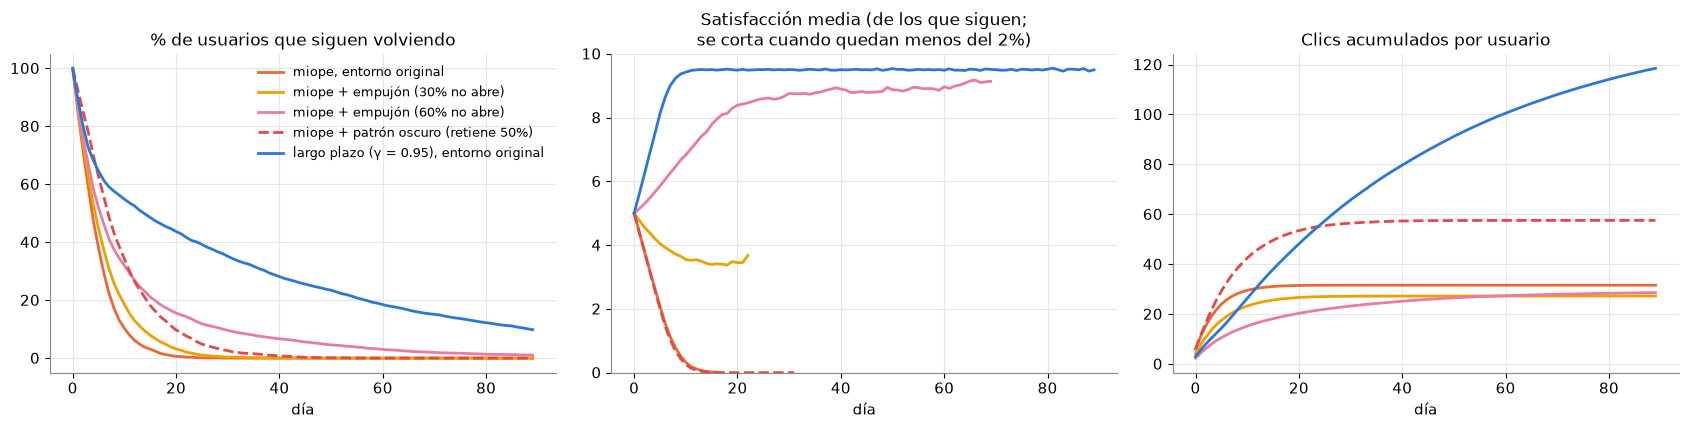

,% activos día 30,satisfacción media día 10,clics en 90 días
escenario,,,
"miope, entorno original",0.0,0.3,31.6
miope + empujón (30% no abre),0.4,3.5,27.2
miope + empujón (60% no abre),9.6,6.8,28.6
miope + patrón oscuro (retiene 50%),2.6,0.3,57.6
"largo plazo (γ = 0.95), entorno original",35.2,9.4,118.5


In [28]:
P_feed, R_feed = feed_mdp()
pi_miope = value_iteration(P_feed, R_feed, 0)[1][:NSAT]          # γ = 0: siempre gancho
pi_largo = value_iteration(P_feed, R_feed, 0.95)[1][:NSAT]
print("Feed miope (γ = 0):          ", " ".join(TIPOS[a] for a in pi_miope))
print("Feed de largo plazo (γ = 0.95):", " ".join(TIPOS[a] for a in pi_largo), "\n")
tabla_feed = comparar_entornos({
    "miope, entorno original": (pi_miope, 0.0, 0.0),
    "miope + empujón (30% no abre)": (pi_miope, 0.3, 0.0),
    "miope + empujón (60% no abre)": (pi_miope, 0.6, 0.0),
    "miope + patrón oscuro (retiene 50%)": (pi_miope, 0.0, 0.5),
    "largo plazo (γ = 0.95), entorno original": (pi_largo, 0.0, 0.0)})
tabla_feed

El agente es **exactamente el mismo** en las cuatro primeras filas (siempre gancho); lo que cambió es el entorno. Lean la tabla:

- el **empujón** frena la caída de la satisfacción y a la plataforma le cuesta pocos clics;
- el **patrón oscuro** le da a la plataforma más clics y más usuarios activos, mientras la satisfacción se hunde igual: usa el mismo mecanismo (tocar el entorno) **en contra** de la persona;
- ninguno de los dos arregla el problema de fondo: mientras el agente optimice el clic de hoy, el usuario la pasa mal. El feed de largo plazo, sin tocar el entorno, conserva más usuarios y más satisfechos.

**Tensión honesta.** El empujón también es una manipulación: alguien decidió por el usuario que entrar menos era mejor. Incluso la manipulación bienintencionada choca con la **autonomía**.

### Paso 2 — La recompensa a la vista y editable

La salida coherente con este curso (la pregunta de la clase 1: quién elige la recompensa) es que **la propia persona vea y elija qué cuenta como progreso**. Supongamos que el feed le muestra al usuario su recompensa y le deja editarla: cuánto pesan los clics y cuánto su satisfacción. Con una recompensa así, **hasta un agente miope (γ = 0)** hace lo que el usuario quiere.

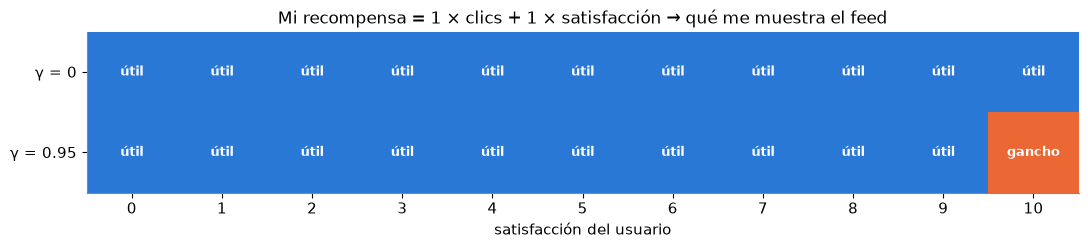

γ = 0   : útil útil útil útil útil útil útil útil útil útil útil
γ = 0.95: útil útil útil útil útil útil útil útil útil útil gancho


In [29]:
# ✍️ Ejercicio: elijan su recompensa (prueben 1 y 0, 1 y 1, 0.2 y 1)
PESO_CLICS = 1.0
PESO_SATISFACCION = 1.0
politica_con_mi_recompensa(PESO_CLICS, PESO_SATISFACCION)

Con `PESO_SATISFACCION = 0` vuelve el gancho para γ = 0; con un peso a la satisfacción, el contenido útil aparece incluso sin mirar el futuro (lean las dos filas impresas). **Ver y editar la propia recompensa** reemplaza buena parte de la planificación a largo plazo que en la clase 3 hacía falta para no "quemar" al usuario, y deja la decisión en manos de quien la sufre.

Para el tutor de la sección 4, lo mismo: que el alumno vea en pantalla qué cuenta el tutor como progreso (¿aciertos? ¿mejora? ¿en qué temas?) y pueda cambiarlo.

## 6. Tres alineaciones para el mismo agente

"Alinear un agente con la persona" suena claro hasta que hay que escribir la recompensa. Hay al menos tres respuestas distintas:

1. **Con lo que pide**: sus intenciones declaradas ("quiero aprender a programar").
2. **Con lo que hace**: sus **preferencias reveladas**, lo que el registro muestra que elige. Es lo que optimiza el feed de las clases 1 y 3.
3. **Con lo que le conviene**: su bienestar o sus intereses a largo plazo, aunque no lo pida ni lo elija.

### Paso 1 — Un ejemplo chico: Lucía a la noche

Un agente elige qué mostrarle a Lucía cada noche: **videos cortos**, **el curso de programación** que ella pidió, o **sugerir cortar** e irse a dormir. Estado: si esa noche está **cansada** o **descansada**, y lo que hace hoy cambia cómo llega mañana. Todos los números son **inventados**:

| | P(mañana descansada) cansada / descansada | P(clic) cansada / descansada | aprende cansada / descansada |
|---|---|---|---|
| videos cortos | 0.15 / 0.30 | 0.85 / 0.75 | 0 / 0 |
| curso de programación | 0.40 / 0.70 | 0.10 / 0.40 | 0.1 / 1 |
| sugerir cortar | 0.90 / 0.95 | 0.05 / 0.05 | 0 / 0 |

El agente **no conoce** la columna de clics: la estima de un registro de 3000 noches pasadas. Las tres recompensas:

- **lo que pide**: 1 si le muestra el curso, 0 si no;
- **lo que hace**: la tasa de clic estimada del registro;
- **lo que le conviene**: lo que aprende.

Las tres usan las **mismas transiciones**; resolvemos cada MDP con iteración de valor, γ = 0.9.

Preferencias reveladas (tasa de clic estimada del registro):
contenido   curso de programación  sugerir cortar  videos cortos
energía                                                         
cansada                      0.10            0.05           0.87
descansada                   0.37            0.05           0.76 



alinear con lo que pide          cansada → curso de programación  descansada → curso de programación


alinear con lo que hace          cansada → videos cortos          descansada → videos cortos


alinear con lo que le conviene   cansada → sugerir cortar         descansada → curso de programación

                    % de noches con lo que pidió  % de noches con clic  \
lo que pide                                100.0                  27.0   
lo que hace                                  0.0                  83.2   
lo que le conviene                          74.0                  31.0   

                    aprendizaje (sesiones buenas)  % de noches descansada  
lo que pide                                  36.3                    56.1  
lo que hace                                   0.0                    17.2  
lo que le conviene                           44.4                    74.0  


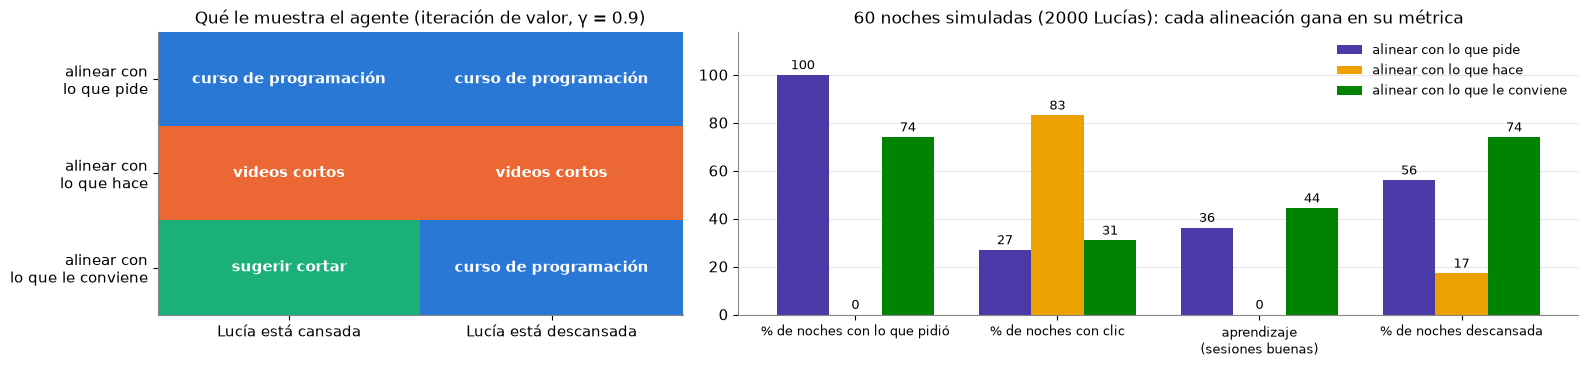

In [30]:
reg = registro_lucia()
print("Preferencias reveladas (tasa de clic estimada del registro):")
print(reg.groupby(["energía", "contenido"]).clic.mean().unstack().round(2), "\n")
P_lucia = mdp_lucia()
R_lucia = recompensas_lucia(reg)
pol_lucia, met_lucia = {}, {}
for nombre, R in R_lucia.items():
    V, pi, Q = value_iteration(P_lucia, R, 0.9)
    pol_lucia[nombre] = pi
    met_lucia[nombre] = simular_lucia(pi)
    print(f"alinear con {nombre:20s} cansada → {ACC_LUCIA[pi[0]]:22s} descansada → {ACC_LUCIA[pi[1]]}")
print()
print(pd.DataFrame(met_lucia).T.round(1))
dibujar_alineaciones(pol_lucia, met_lucia)

**Tres recompensas, tres políticas distintas para el mismo agente y la misma persona:**

- alineado con **lo que pide**, le muestra el curso siempre, aunque esté cansada y no le sirva;
- alineado con **lo que hace**, le muestra videos cortos siempre: es el feed, y Lucía duerme mal;
- alineado con **lo que le conviene**, le sugiere cortar cuando está cansada y le muestra el curso cuando está descansada: aprende más que con las otras dos, pero esa política **contradice lo que ella pidió** las noches en que está cansada y le da muchos menos clics que los videos.

Cada alineación gana en su propia métrica (lean la tabla). Ninguna es neutral:

- "lo que pide" ignora que las personas no siempre saben o no siempre dicen lo que quieren;
- "lo que hace" confunde lo que alguien elige a las 2 de la mañana con lo que quiere;
- "lo que le conviene" exige que **alguien** decida qué le conviene a Lucía: si lo decide la plataforma, es paternalismo.

Una salida, la de la sección 5: que Lucía **vea las tres recompensas y elija la mezcla**. El agente puede proponer; la recompensa es de ella.

### ✍️ Ejercicio

Armen una recompensa mezcla: `PESO_PIDE × pide + PESO_HACE × hace + PESO_CONVIENE × conviene`. ¿Qué mezcla elegirían para ustedes? ¿Hay alguna que dé una política distinta de las tres de arriba?

In [31]:
# TODO: cambiar los pesos y volver a ejecutar
PESO_PIDE, PESO_HACE, PESO_CONVIENE = 0.3, 0.3, 0.4
R_mia = PESO_PIDE * R_lucia["lo que pide"] + PESO_HACE * R_lucia["lo que hace"] + PESO_CONVIENE * R_lucia["lo que le conviene"]
pi_mia = value_iteration(P_lucia, R_mia, 0.9)[1]
m = simular_lucia(pi_mia)
print(f"cansada → {ACC_LUCIA[pi_mia[0]]} · descansada → {ACC_LUCIA[pi_mia[1]]}")
print({k: round(v, 1) for k, v in m.items()})

cansada → curso de programación · descansada → curso de programación
{'% de noches con lo que pidió': np.float64(100.0), '% de noches con clic': np.float64(27.0), 'aprendizaje (sesiones buenas)': np.float64(36.3), '% de noches descansada': np.float64(56.1)}


## Preguntas para pensar

1. ¿Qué app que usás todos los días te gustaría que cobrara por otra cosa? ¿Qué le pondrías como recompensa, y cómo te podría hacer trampa con esa?
2. El evaluador de la fábrica es otro modelo de lenguaje. ¿Qué pasaría si el generador se entrenara con RL para **maximizar el puntaje del evaluador**? (Pista: la recompensa aprendida de la clase 12.)
3. En el ejemplo de Lucía, ¿quién debería poder escribir "lo que le conviene": ella, la plataforma, un médico, sus amigos? ¿Qué cambia en cada caso?

## Próxima clase

Clase 16, la última: **cierre**. El recorrido entero sobre la cueva, el proyecto final ("el MDP de tu dominio") y cómo se propaga este curso, que también es un agente de difusión: elegimos que su recompensa sea que alguien aprenda y se lo enseñe a otra persona.

In [32]:
print(f"Tiempo total del notebook: {(time.time() - T0) / 60:.1f} min · generador: {GENERADOR_USADO} · evaluador: {MODELO_EVALUADOR}")

Tiempo total del notebook: 13.8 min · generador: Qwen/Qwen2.5-0.5B-Instruct · evaluador: Qwen/Qwen2.5-1.5B-Instruct
